In [22]:
# Import required libraries
!pip install kds
!pip install xgboost

import kds
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, roc_auc_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Set display options for better readability
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

In [23]:
#import dataset and save it to customer
customer=pd.read_csv("datafile_small.csv")
customer.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16,var_17,var_18,var_19,var_20,var_21,var_22,var_23,var_24,var_25,var_26,var_27,var_28,var_29,var_30,var_31,var_32,var_33,var_34,var_35,var_36,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49,var_50,var_51,var_52,var_53,var_54,var_55,var_56,var_57,var_58,var_59,var_60,var_61,var_62,var_63,var_64,var_65,var_66,var_67,var_68,var_69,var_70,var_71,var_72,var_73,var_74,var_75,var_76,var_77,var_78,var_79,var_80,var_81,var_82,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_90,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100,var_101,var_102,var_103,var_104,var_105,var_106,var_107,var_108,var_109,var_110,var_111,var_112,var_113,var_114,var_115,var_116,var_117,var_118,var_119,var_120,var_121,var_122,var_123,var_124,var_125,var_126,var_127,var_128,var_129,var_130,var_131,var_132,var_133,var_134,var_135,var_136,var_137,var_138,var_139,var_140,var_141,var_142,var_143,var_144,var_145,var_146,var_147,var_148,var_149,var_150,var_151,var_152,var_153,var_154,var_155,var_156,var_157,var_158,var_159,var_160,var_161,var_162,var_163,var_164,var_165,var_166,var_167,var_168,var_169,var_170,var_171,var_172,var_173,var_174,var_175,var_176,var_177,var_178,var_179,var_180,var_181,var_182,var_183,var_184,var_185,var_186,var_187,var_188,var_189,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,4526.0,0,9.9776,5.5923,11.4438,5.5590,10.3671,-14.2323,5.2197,17.4772,-0.8589,6.4466,-2.0181,-0.7475,13.9520,10.6570,3.9615,15.0847,6.0334,-20.0406,10.6374,23.0243,11.0180,36.6724,9.7023,3.3333,11.9782,13.2091,-5.2089,-0.6168,7.0143,9.4478,-7.2299,9.8983,-2.6470,14.6332,11.5930,7.5856,2.9078,4.9367,14.6494,-1.2284,-19.6810,-0.5483,10.8152,11.6397,11.2751,-30.9989,11.7720,0.8519,17.6226,13.7595,12.1928,-4.4225,2.5443,7.3619,-5.1983,11.9567,18.5768,5.8279,1.2811,7.9057,22.5688,-6.4633,-1.0539,3.1257,8.7343,5.2592,6.6835,16.6426,5.0291,-7.6547,26.2927,0.3375,-3.0081,17.2052,33.6179,9.8539,12.1382,13.8419,0.9657,12.6201,12.2613,14.3767,-7.5107,1.6170,7.1560,15.9229,10.9619,6.1356,7.2192,6.6483,-10.1242,6.7982,9.4795,9.9928,7.8905,0.1370,30.5995,12.0785,2.1698,2.4023,-6.6062,21.8551,28.3727,1.5230,8.9136,4.9149,7.3830,22.8002,13.9230,26.0074,5.7573,7.1535,3.2990,11.1780,2.9056,7.5032,2.2089,42.3121,-5.4775,7.7076,31.8708,14.1632,-5.9061,-0.3355,6.9084,12.9392,14.4271,3.7253,-0.9610,18.5371,11.3663,0.6839,8.5192,6.6473,-1.3320,-3.9629,34.2576,28.9069,8.0029,4.3576,-0.2362,0.7472,21.1170,10.1820,8.8113,0.4291,10.9394,-10.2479,4.3863,-6.7024,16.1017,7.1432,7.3160,16.4369,-5.6886,8.3458,11.4837,7.9991,24.5457,9.6002,8.3240,5.7873,4.6019,13.9549,-4.2643,16.6678,2.6221,12.5663,5.8303,6.0400,-2.3568,3.1876,11.7161,5.7909,8.3170,15.1610,8.4922,6.6531,8.8954,1.3848,-1.5666,11.7596,11.0817,4.8265,10.6667,-8.5397,5.0467,-23.2499,11.1468,2.4356,4.2696,4.2182,2.7052,-4.4353,16.2225,-1.1783,9.4155,7.7390,14.1050,10.1240
1,13796.0,0,12.4537,4.3320,12.9258,10.0072,11.4524,-0.6389,4.2284,16.8380,-5.1487,4.5864,-2.4220,-4.2308,14.1141,8.5106,5.8239,14.5934,14.1132,-10.5524,24.7634,16.4075,7.2949,14.2005,11.3745,3.7669,9.5724,13.7108,-11.8148,-0.3865,6.4120,3.0074,-21.4513,7.5371,-0.7282,13.3268,11.5210,-5.6640,1.7181,8.2460,7.5625,8.6365,-7.2283,6.4408,11.3364,11.7308,-5.3147,16.9514,13.2289,-9.7411,27.1470,24.9166,13.0619,1.6505,0.9334,6.6130,-2.4221,20.7715,16.8904,6.8055,6.0992,8.8190,12.6406,-10.7856,4.1143,-2.9431,3.4594,-3.6253,6.1935,0.7863,5.0147,-7.9161,46.6222,0.8988,-3.0708,13.0234,26.3454,16.0786,0.6751,12.5131,2.1744,13.0125,-7.4552,15.4555,5.9254,5.7717,5.5594,25.3848,5.1703,19.8334,9.6198,5.1793,-29.9869,7.1823,14.1794,10.1460,8.1801,-0.1133,2.9399,4.8060,2.0670,1.3278,-15.2822,7.4587,15.7739,1.3970,10.2645,3.9449,7.5948,13.4220,13.9449,12.2584,-2.7916,5.0617,-0.3828,7.6305,4.1643,1.3154,0.9218,2.4012,5.7809,3.1593,21.2488,14.0054,-0.9716,2.4810,3.4999,12.

In [24]:
#Check unique values of the target column
customer.info()
customer["target"].unique()

#Check the summary of the dataset
print("\nData Summary:\n")
print(customer.describe(include='all'))
customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Columns: 202 entries, ID_code to var_199
dtypes: float64(201), int64(1)
memory usage: 30.8 MB

Data Summary:

             ID_code        target         var_0         var_1         var_2  \
count   20000.000000  20000.000000  20000.000000  20000.000000  20000.000000   
mean    99111.483750      0.098200     10.674606     -1.655749     10.704494   
std     57762.831745      0.297592      3.022318      4.038984      2.645574   
min         6.000000      0.000000      0.408400    -13.006000      2.789200   
25%     48602.750000      0.000000      8.459100     -4.805050      8.717850   
50%     98938.000000      0.000000     10.548350     -1.665950     10.566500   
75%    148979.250000      0.000000     12.745800      1.362150     12.504875   
max    199996.000000      1.000000     19.331500      8.614600     19.353000   

              var_3         var_4         var_5         var_6         var_7  \
count  20000.0

In [25]:
#print("\nNull Counts:")
missing_counts = customer.isnull().sum()
print(missing_counts)

#sum all columns include missing value
print("Total missing:", customer.isna().sum().sum())
print(customer.isna().sum()[customer.isna().sum() > 0])
customer[customer.isna().any(axis=1)]


ID_code    0
target     0
var_0      0
var_1      0
var_2      0
          ..
var_195    0
var_196    0
var_197    0
var_198    0
var_199    0
Length: 202, dtype: int64
Total missing: 10110
var_12        1
var_18        1
var_33        1
var_41        2
var_45     8034
var_76     1031
var_87        1
var_93        1
var_96     1031
var_103       1
var_108       1
var_121       1
var_134       1
var_166       1
var_180       1
var_185       1
dtype: int64


,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16,var_17,var_18,var_19,var_20,var_21,var_22,var_23,var_24,var_25,var_26,var_27,var_28,var_29,var_30,var_31,var_32,var_33,var_34,var_35,var_36,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49,var_50,var_51,var_52,var_53,var_54,var_55,var_56,var_57,var_58,var_59,var_60,var_61,var_62,var_63,var_64,var_65,var_66,var_67,var_68,var_69,var_70,var_71,var_72,var_73,var_74,var_75,var_76,var_77,var_78,var_79,var_80,var_81,var_82,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_90,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100,var_101,var_102,var_103,var_104,var_105,var_106,var_107,var_108,var_109,var_110,var_111,var_112,var_113,var_114,var_115,var_116,var_117,var_118,var_119,var_120,var_121,var_122,var_123,var_124,var_125,var_126,var_127,var_128,var_129,var_130,var_131,var_132,var_133,var_134,var_135,var_136,var_137,var_138,var_139,var_140,var_141,var_142,var_143,var_144,var_145,var_146,var_147,var_148,var_149,var_150,var_151,var_152,var_153,var_154,var_155,var_156,var_157,var_158,var_159,var_160,var_161,var_162,var_163,var_164,var_165,var_166,var_167,var_168,var_169,var_170,var_171,var_172,var_173,var_174,var_175,var_176,var_177,var_178,var_179,var_180,var_181,var_182,var_183,var_184,var_185,var_186,var_187,var_188,var_189,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
7,3791.0,0,4.5242,-8.5240,12.2836,4.9625,9.0924,3.0963,5.8616,20.9978,5.5031,6.3610,0.1628,3.6078,13.8967,10.7965,5.1916,13.8767,9.6734,-1.5355,3.5991,11.7930,14.2037,23.7548,7.1439,3.1655,16.8615,13.7566,-6.3602,-1.5628,6.1188,1.5235,-12.3506,13.1584,-3.3248,9.1204,11.6362,14.3107,4.5529,5.6980,14.5378,2.8885,-2.1654,10.1090,11.5047,11.2504,12.6892,NaN,12.6133,1.2593,11.6355,19.5551,12.4384,15.0763,5.5593,6.0238,2.7456,18.8981,21.7282,6.9392,0.7870,9.7431,15.8346,-16.3495,1.1962,5.6434,3.7050,0.5086,5.1344,10.2369,5.0055,-6.4814,41.6296,0.4239,0.1259,14.0259,17.0612,26.2779,3.0863,27.5559,3.9446,14.0200,3.3088,15.7485,-9.8263,1.6357,3.3996,21.3439,8.7359,12.9405,3.0826,8.7161,-13.2737,6.9685,17.0301,10.9511,7.9539,0.0219,23.3969,15.6960,1.3150,-1.2056,-3.2888,12.3693,25.6208,1.5350,11.0225,4.2357,10.9753,12.6492,14.4732,21.8696,8.1421,5.8994,2.7354,2.8473,3.5239,-3.7271,1.2550,1.7842,-21.7351,-4.2291,37.7501,9.7597,1.9838,15.3987,8.2523,13.2530,13.6111,5.3789,-1.2949,16.4266,13.8799,0.2978,8.9867,6.2079,-3.5953,-13.8437,22.1215,22.3024,2.5270,10.0811,-1.9363,8.2363,17.5412,14.4986,9.3327,0.5103,11.6628,-9.3380,4.2816,3.4220,17.3838,13.7015,10.9031,15.9700,14.7220,2.9670,11.9288,-2.5241,13.2269,11.2780,16.6922,5.6976,3.6057,21.2566,-3.0984,24.7424,3.4733,-9.9999,2.2033,5.3054,-4.7859,-3.9334,4.8208,-6.8758,19.6991,11.0546,-15.7395,8.9250,-3.3135,2.7555,-7.4379,9.8241,6.1701,3.8991,8.1071,-0.2268,8.1514,-5.2726,20.0326,-0.0802,9.3792,11.4869,1.1073,4.2443,17.3824,-1.0610,4.1114,10.4626,15.7257,11.0608
8,85381.0,0,13.9456,6.8692,7.6142,4.7739,9.7856,-11.9261,4.0267,12.7699,-2.7054,8.7391,-6.4577,-5.1921,14.0659,4.0433,8.3325,14.7636,6.9992,-4.9407,5.7672,16.3911,23.2869,15.2138,4.8256,2.5145,10.0744,13.5319,-12.2483,-2.6309,5.8082,6.1517,-0.4902,9.5932,0.7213,7.6038,11.6937,1.4736,-0.6140,8.1205,10.9574,-1.5126,-18.5296,16.5639,10.8653,11.7887,14.1808,NaN,12.3185,9.2957,4.4220,18.2651,13.4142,17.8374,-5.2921,5.1835,11.9499,15.1204,16.8228,7.4190,11.1763,7.9472,11.4636,-34.6158,2.3420,-2.5884,6.8901,2.5504,5.8393,-0.1780,5.0167,-2.9660,30.9911,1.2262,7.1015,17.3853,17.1804,11.1778,16.0260,23.4070,9.3429,17.0396,17.8474,15.1963,-6.8670,9.5171,-3.3121,21.0767,3.8724,3.1874,8.0093,3.2453,-12.5168,6.8407,11.5428,10.8444,11.2966,0.3395,28.9114,41.0093,1.3962,-4.9668,-6.6419,15.3424,10.9153,1.6453,6.6933,5.1099,10.5677,19.7780,14.4312,27.1234,8.1451,6.5508,1.4020,16.0382,4.4593,-3.5457,6.3204,26.8155,-5.9107,3.5702,32.2867,10.6247,-1.5294,4.7747,6.7637,12.814

In [26]:
# Remove columns with high missing rate
missing_threshold = 0.30  

#Calculate missing ratio and identify high missing columns
missing_ratio = customer.isnull().sum() / len(customer)
high_missing_cols = missing_ratio[missing_ratio > missing_threshold].index.tolist()

print(f"Missing threshold: {missing_threshold * 100:.0f}%")
print(f"Columns dropped: {high_missing_cols}")
print(f"Number of columns dropped: {len(high_missing_cols)}")

# Drop high missing rate columns
customer_new = customer.drop(columns=high_missing_cols).copy()

#Impute remaining missing values using mean
num_cols = customer_new.select_dtypes(include=["number"]).columns
cols_to_impute = num_cols[customer_new[num_cols].isnull().any()].tolist()

print(f"\nNumeric columns imputed with median: {len(cols_to_impute)}")
print(f"Columns to impute: {cols_to_impute}")

mean_values = customer_new[cols_to_impute].mean()
data_imputed = customer_new.copy()
data_imputed[cols_to_impute] = data_imputed[cols_to_impute].fillna(mean_values)


before_rows = data_imputed.shape[0]
customer_clean = data_imputed.dropna()
after_rows = customer_clean.shape[0]

print(f"\nFinal dataset shape: {customer_clean.shape}")
print(f"Number of records removed after imputation and final cleanup: {before_rows - after_rows}")
print(f"Total remaining missing values: {customer_clean.isnull().sum().sum()}")


Missing threshold: 30%
Columns dropped: ['var_45']
Number of columns dropped: 1

Numeric columns imputed with median: 15
Columns to impute: ['var_12', 'var_18', 'var_33', 'var_41', 'var_76', 'var_87', 'var_93', 'var_96', 'var_103', 'var_108', 'var_121', 'var_134', 'var_166', 'var_180', 'var_185']

Final dataset shape: (20000, 201)
Number of records removed after imputation and final cleanup: 0
Total remaining missing values: 0


Variables to plot: Index(['var_0', 'var_1', 'var_2', 'var_3', 'var_4', 'var_5', 'var_6', 'var_7',
       'var_8', 'var_9',
       ...
       'var_190', 'var_191', 'var_192', 'var_193', 'var_194', 'var_195',
       'var_196', 'var_197', 'var_198', 'var_199'],
      dtype='object', length=199)


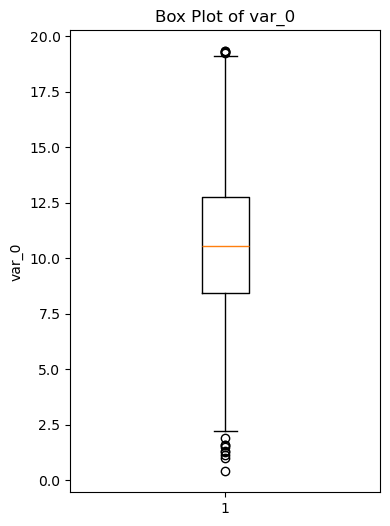

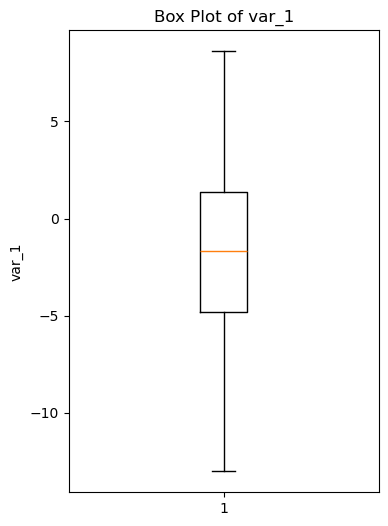

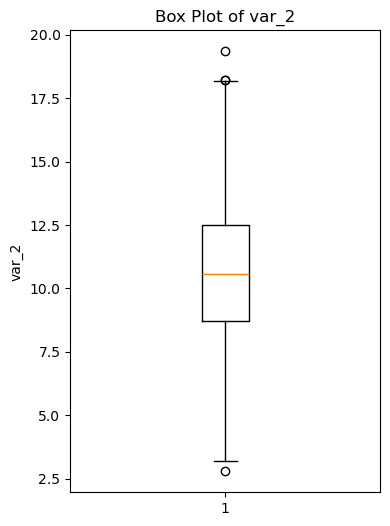

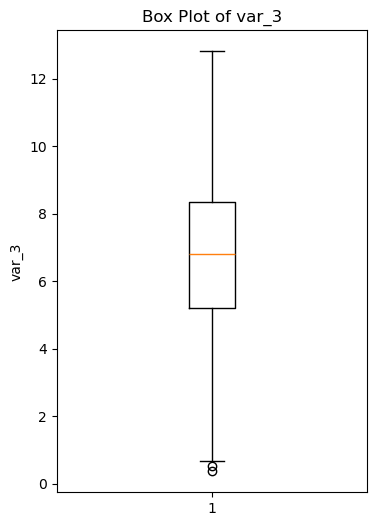

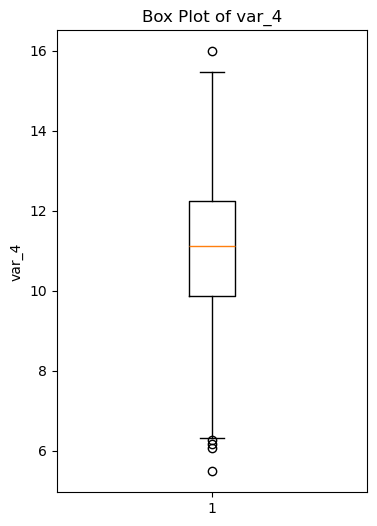

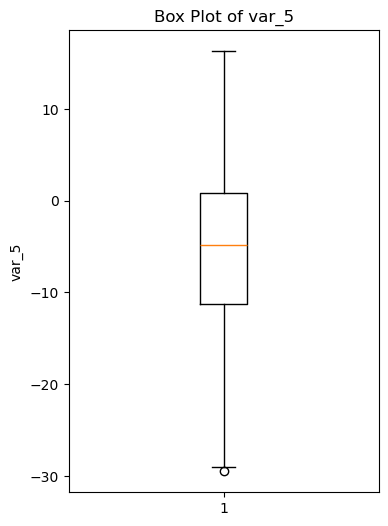

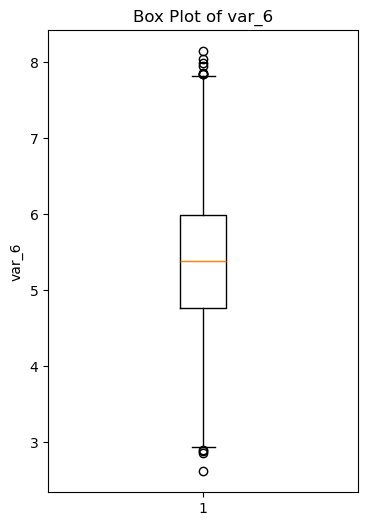

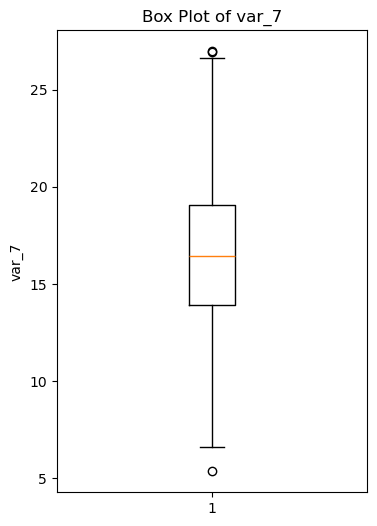

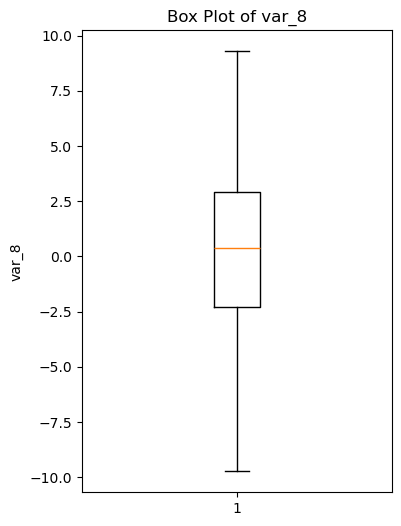

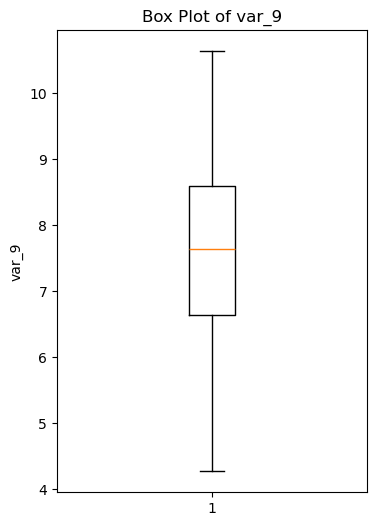

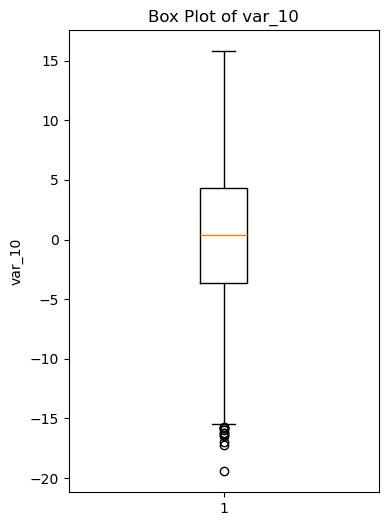

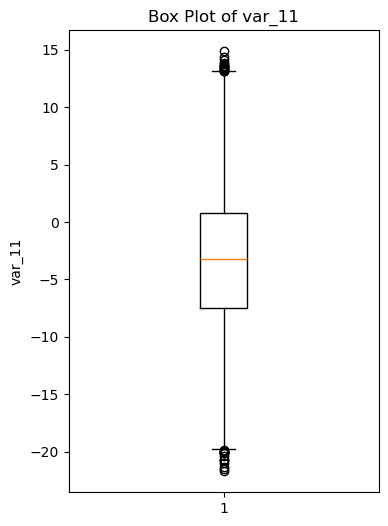

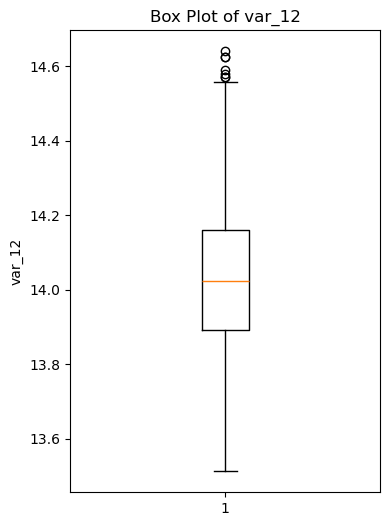

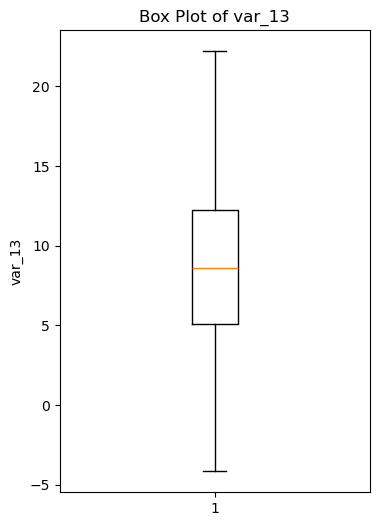

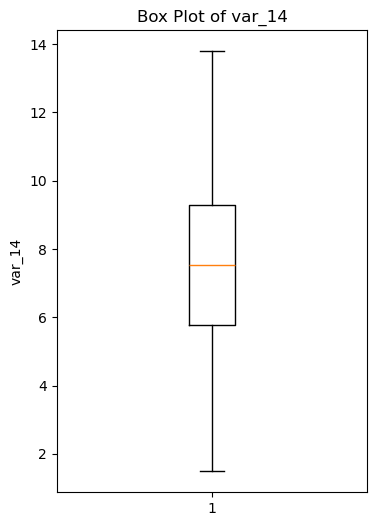

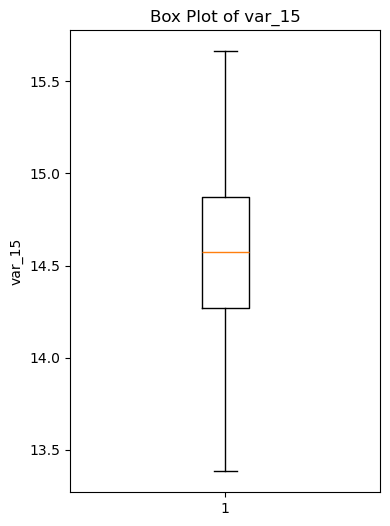

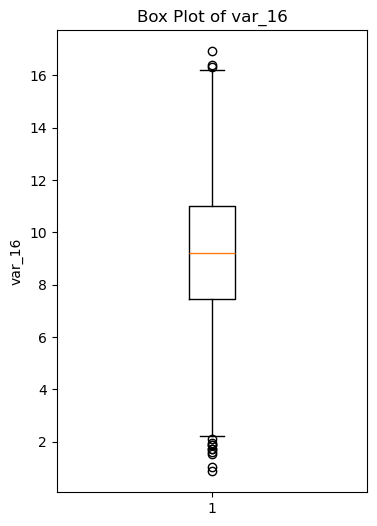

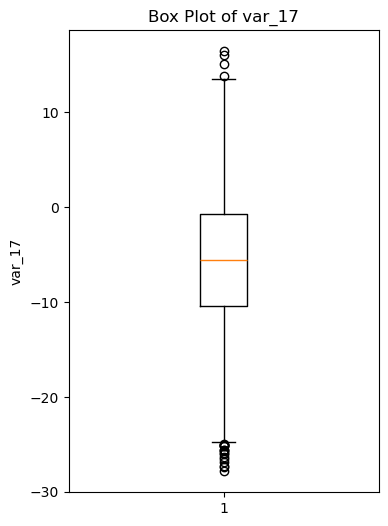

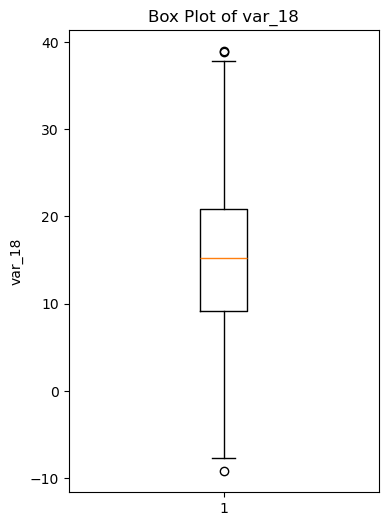

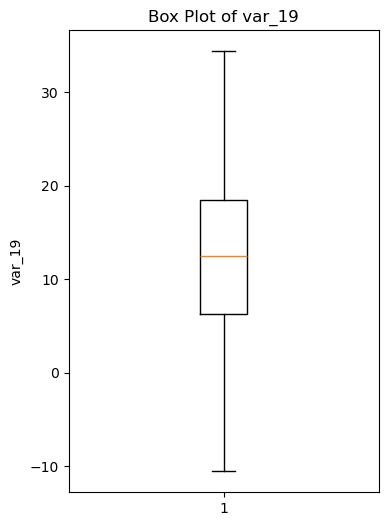

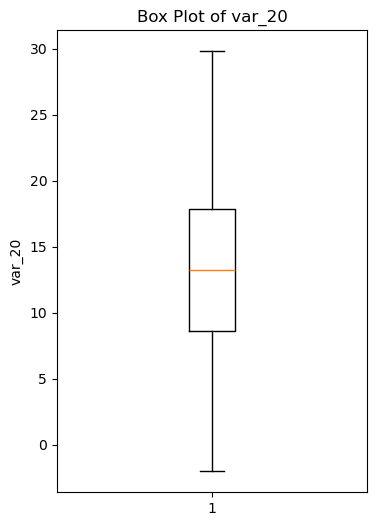

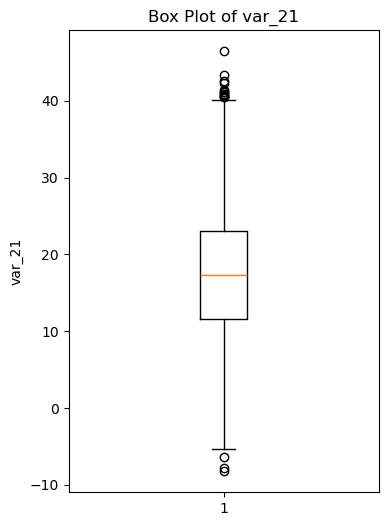

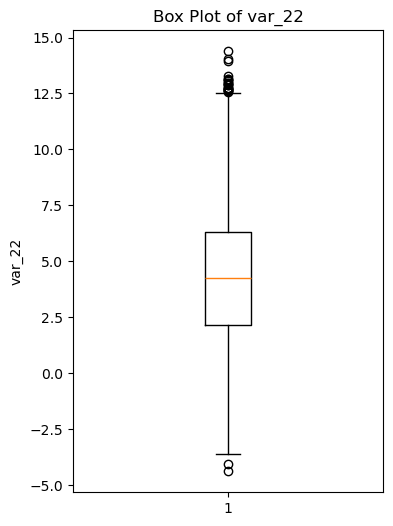

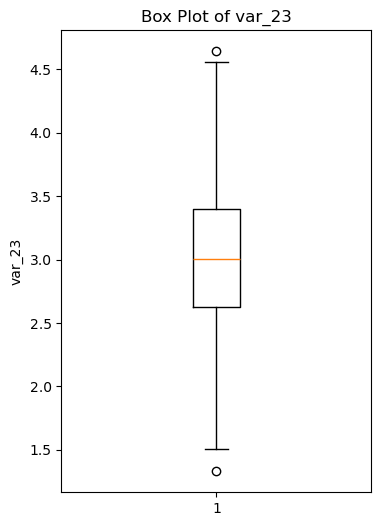

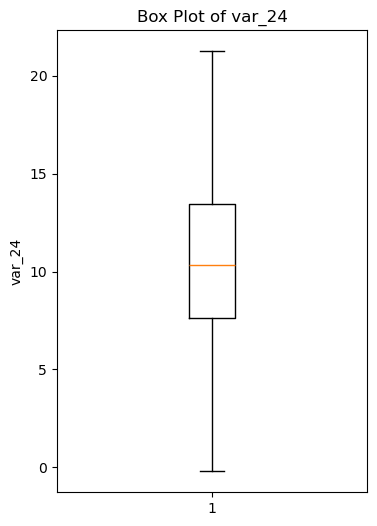

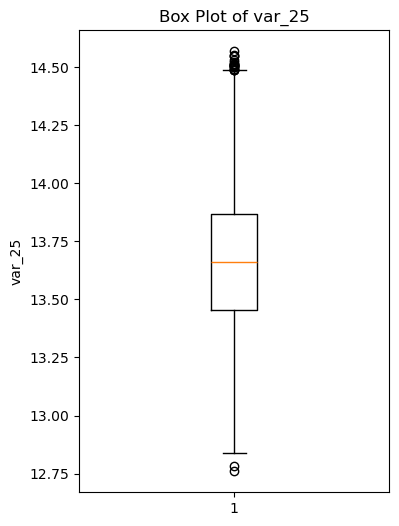

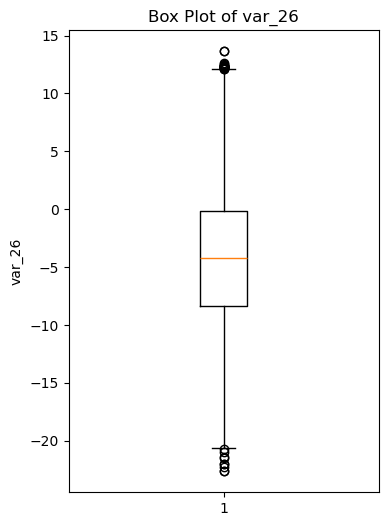

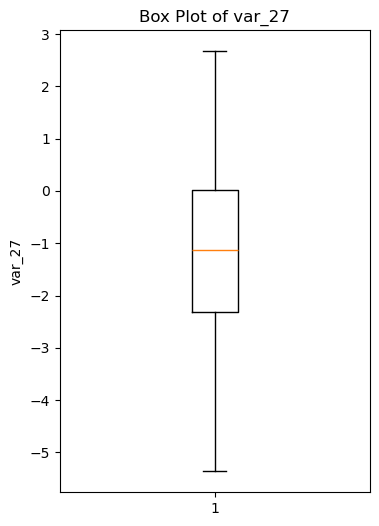

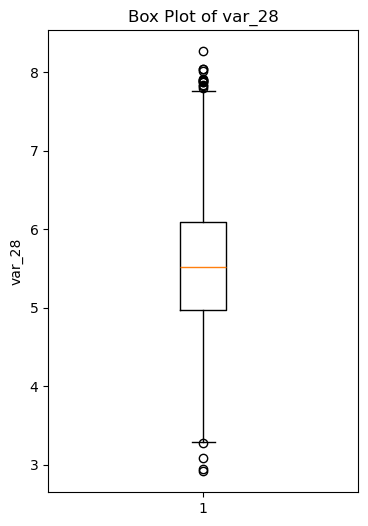

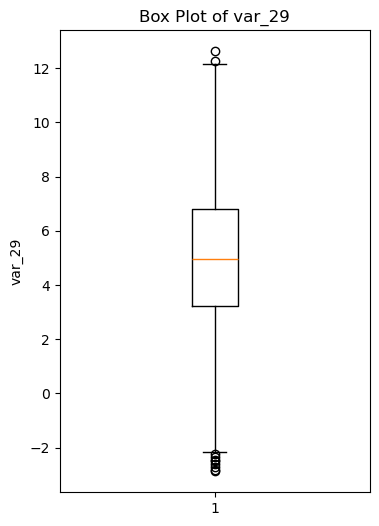

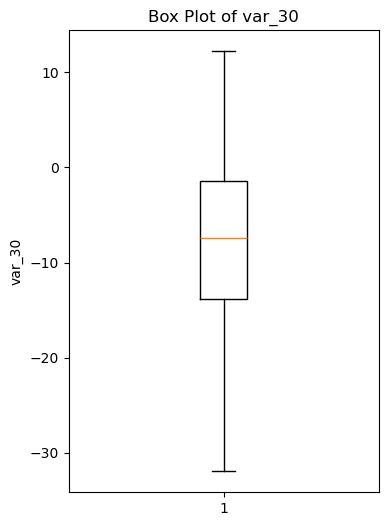

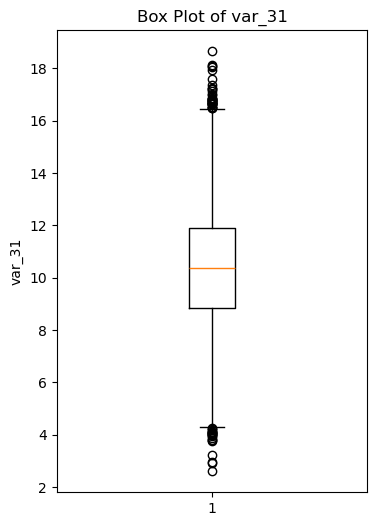

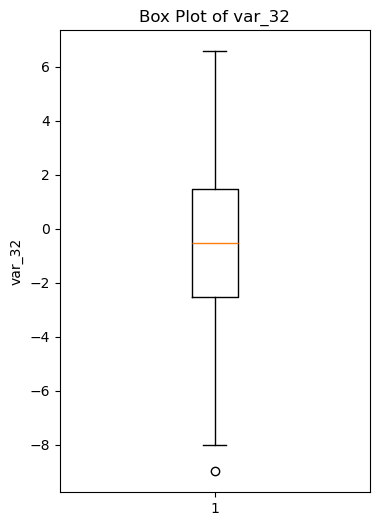

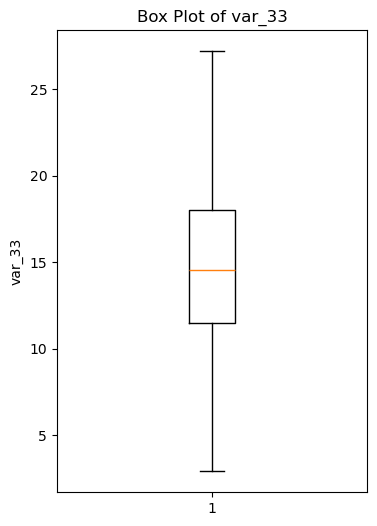

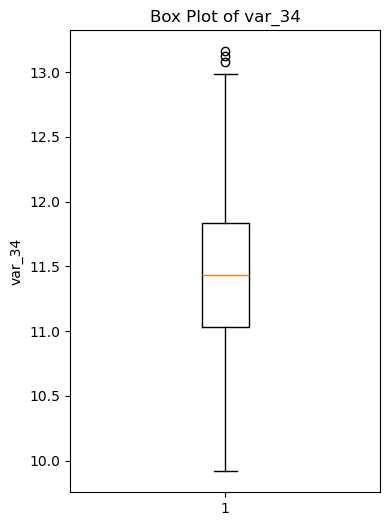

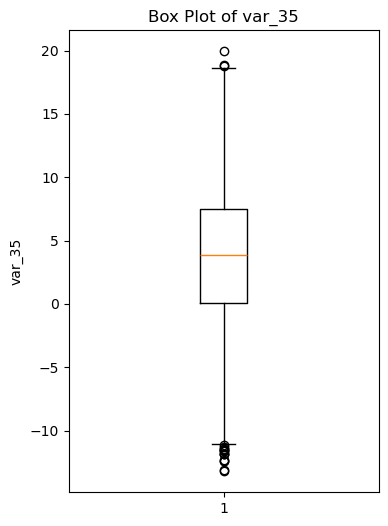

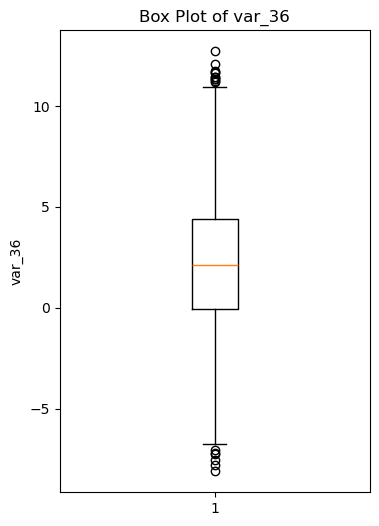

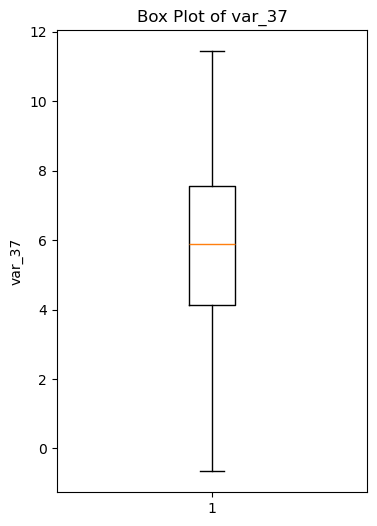

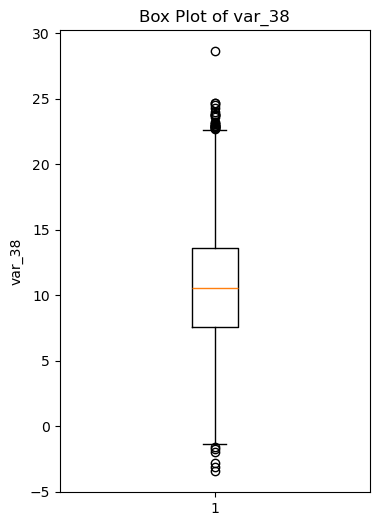

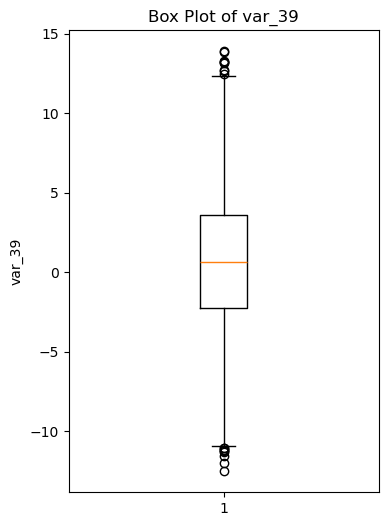

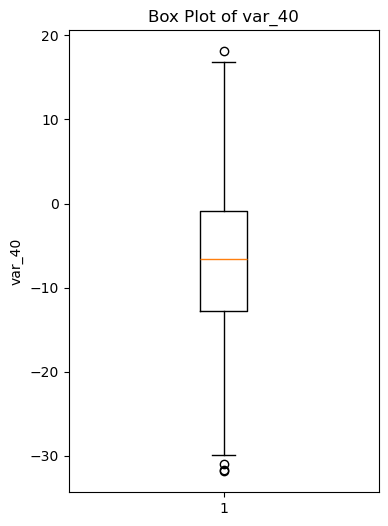

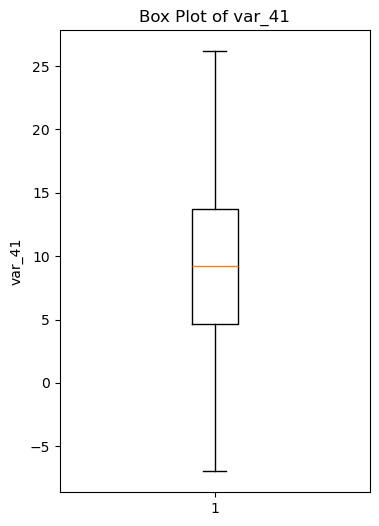

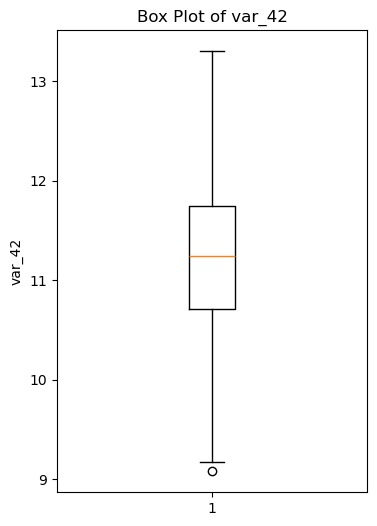

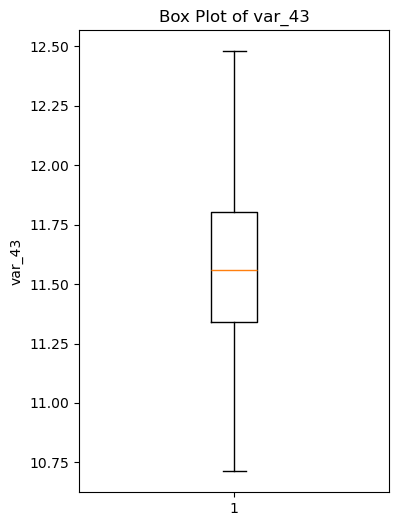

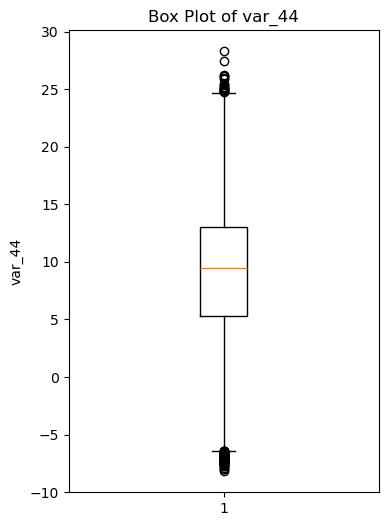

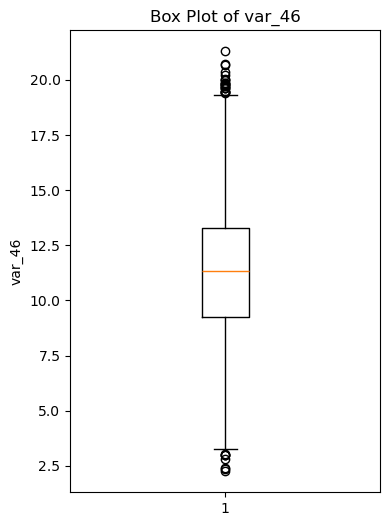

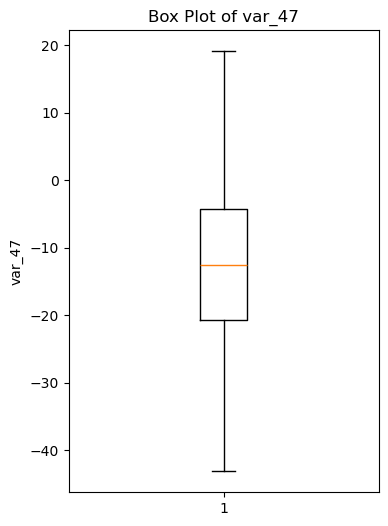

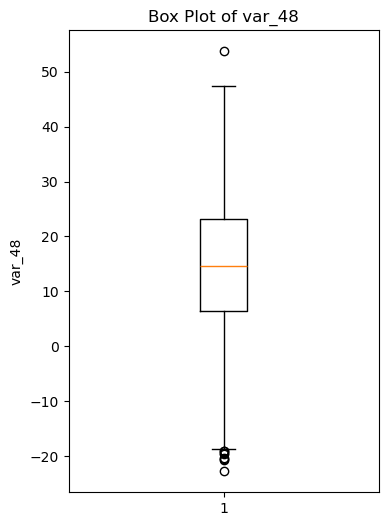

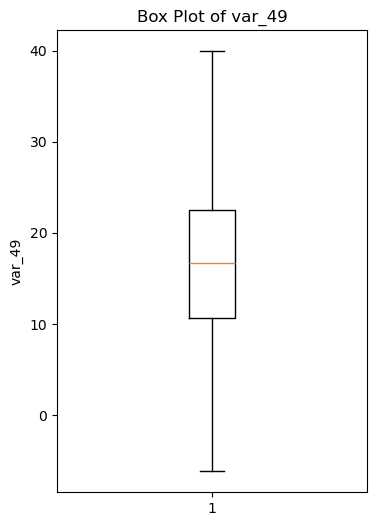

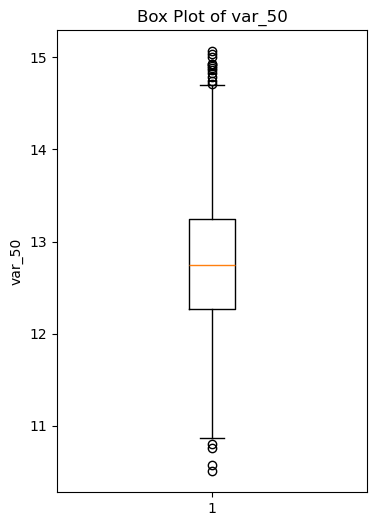

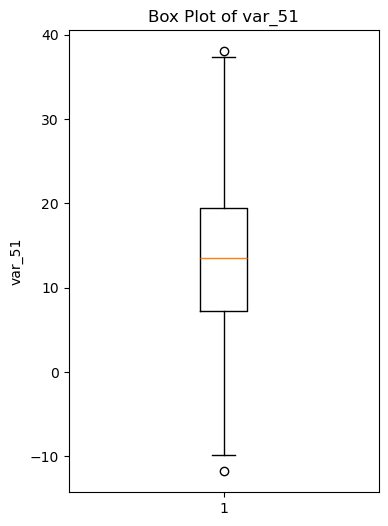

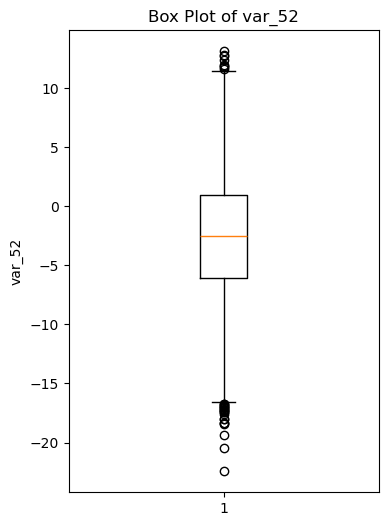

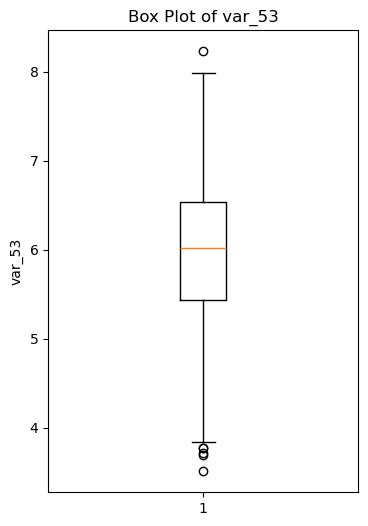

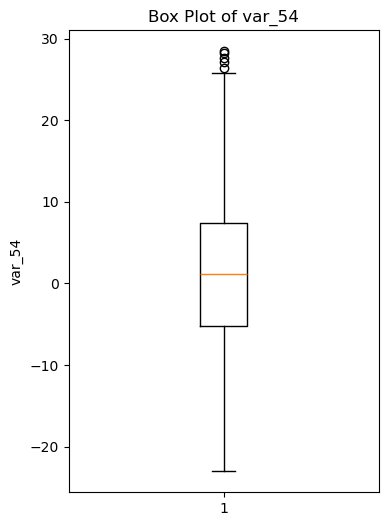

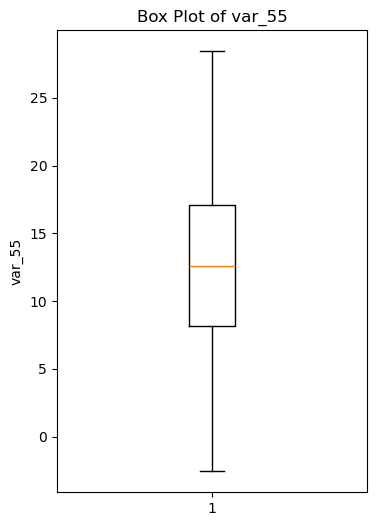

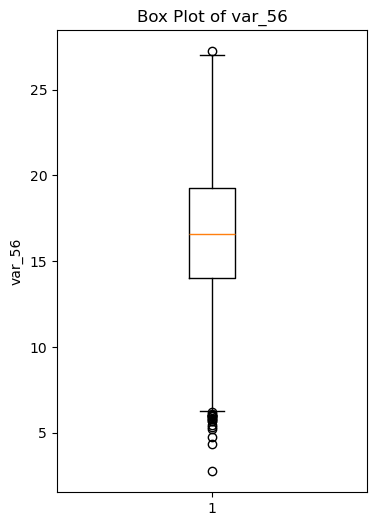

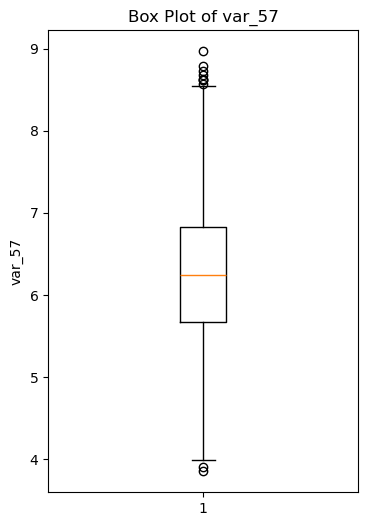

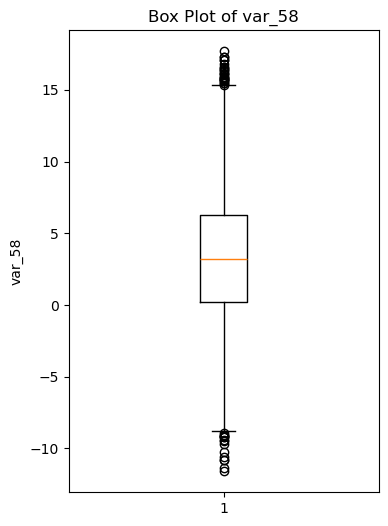

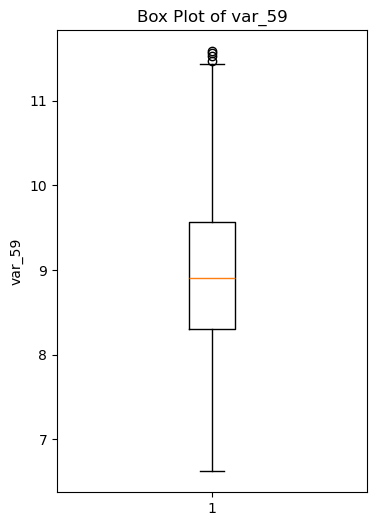

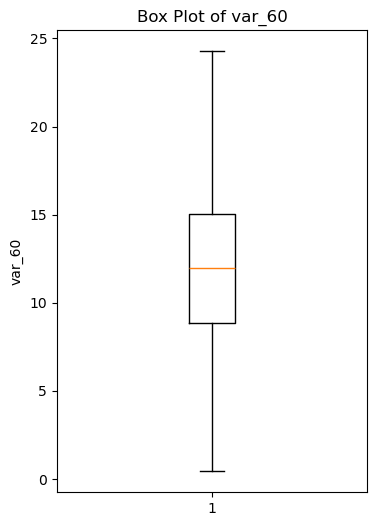

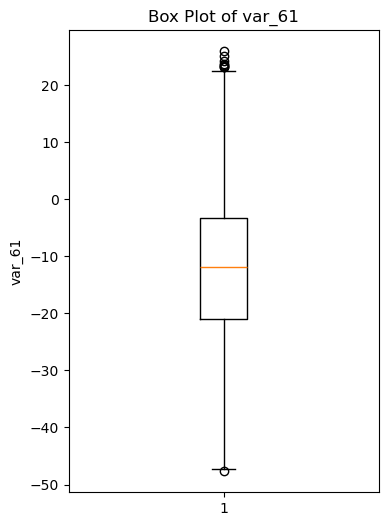

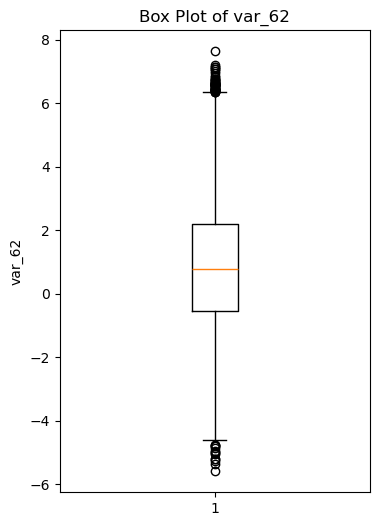

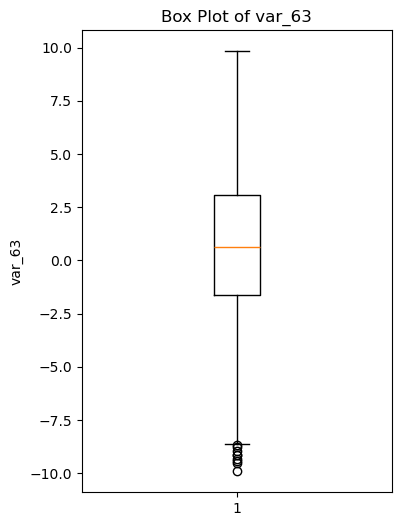

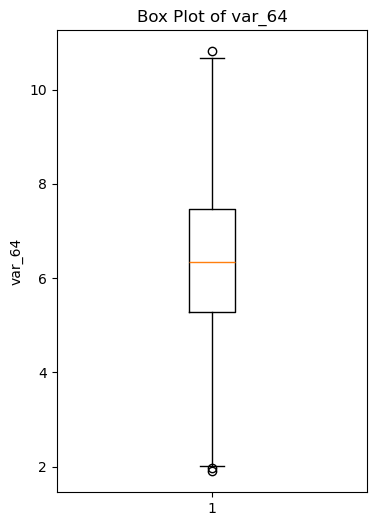

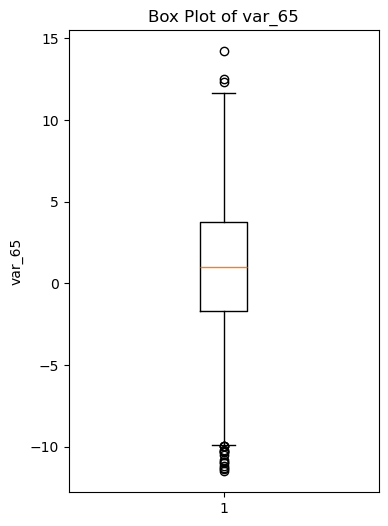

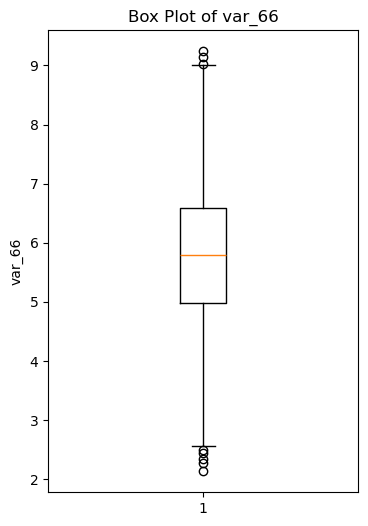

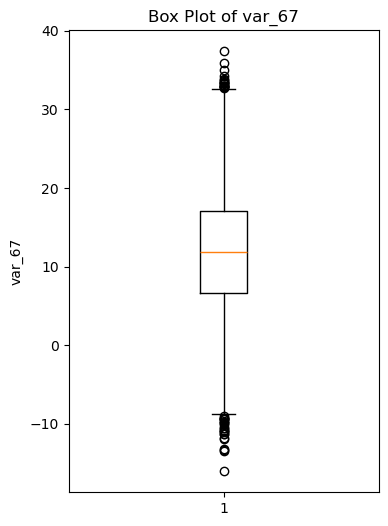

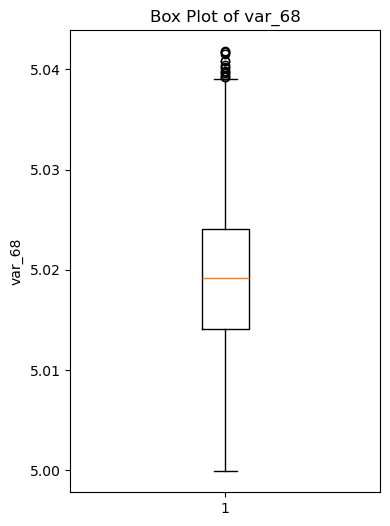

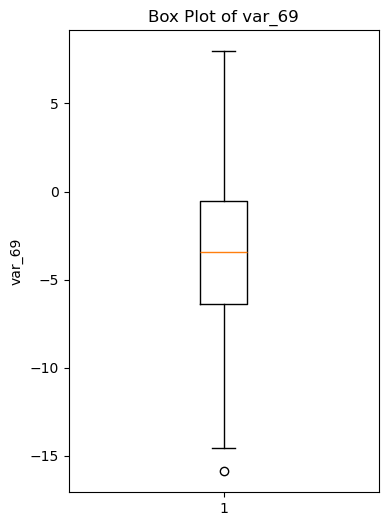

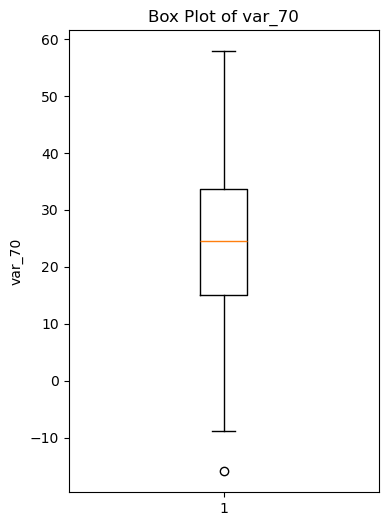

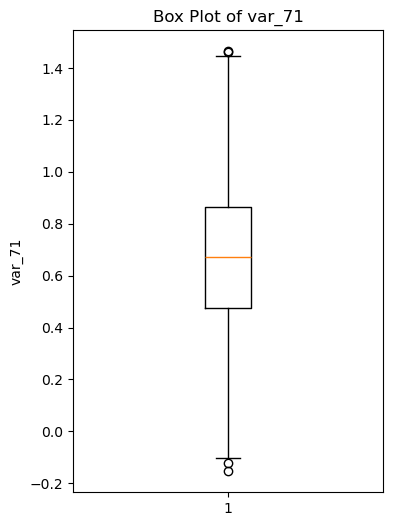

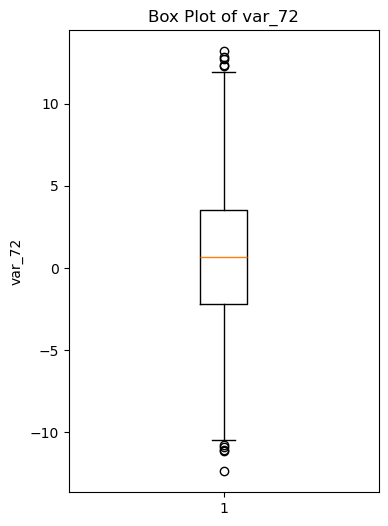

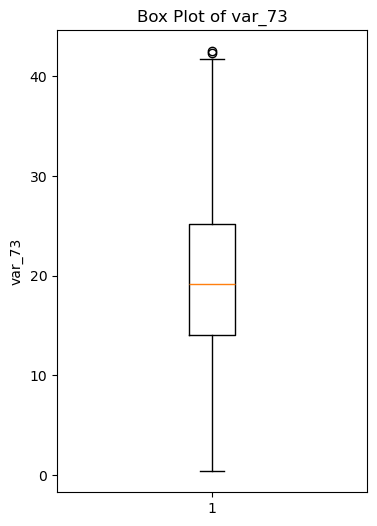

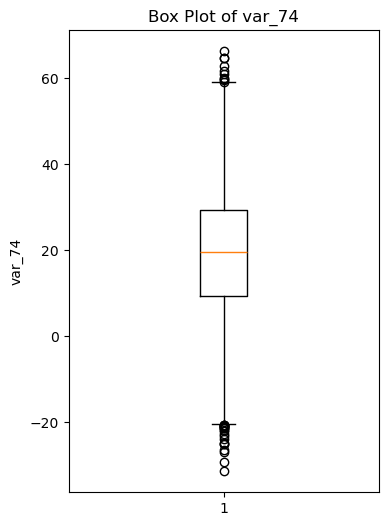

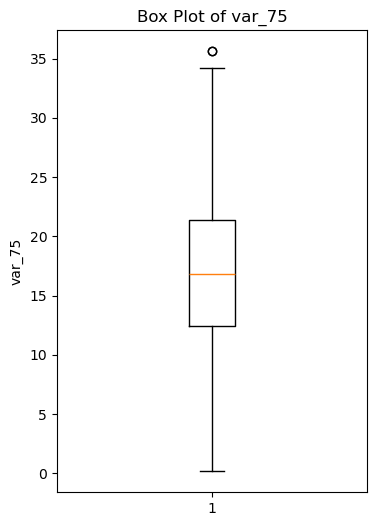

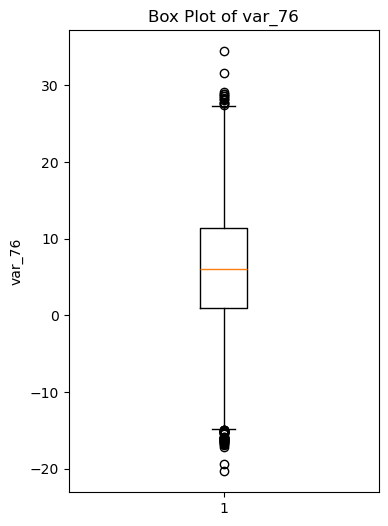

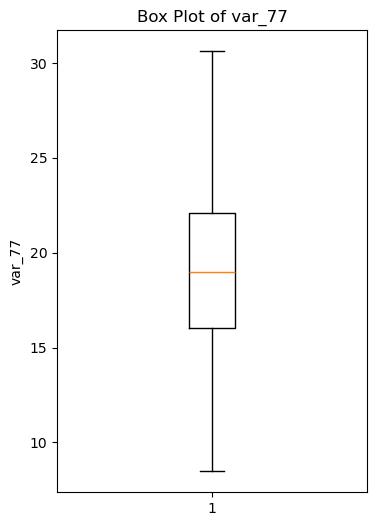

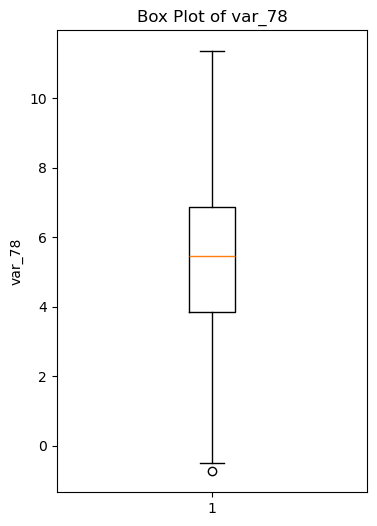

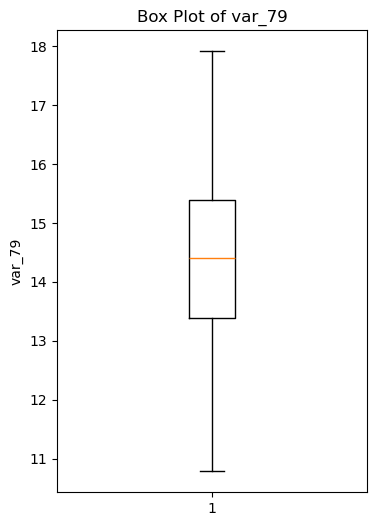

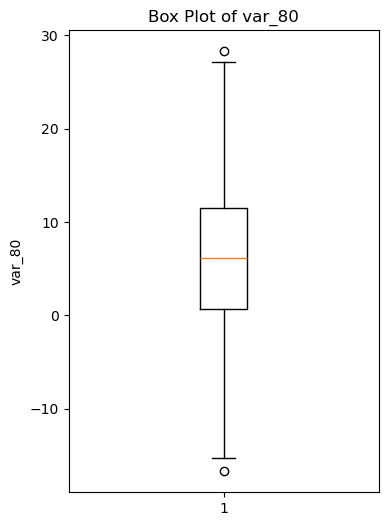

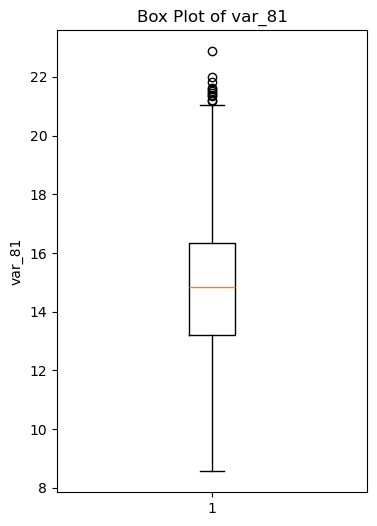

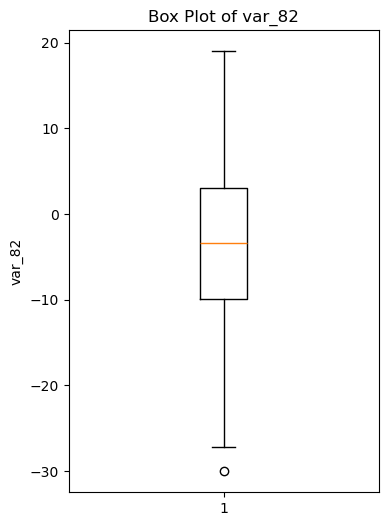

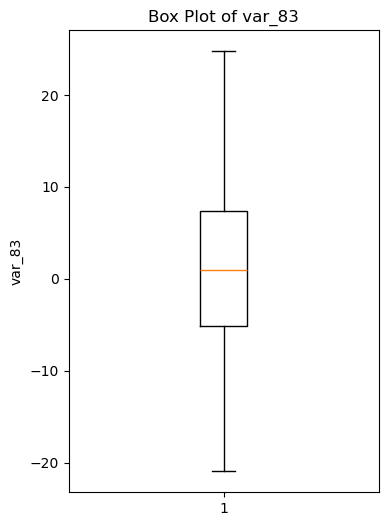

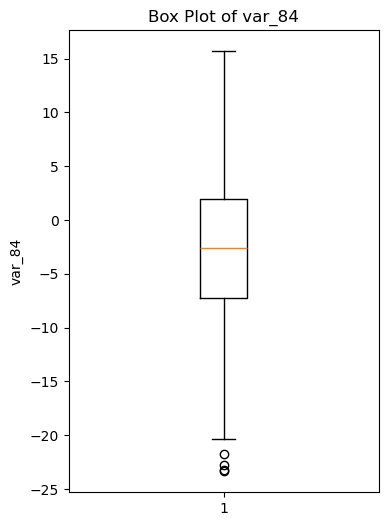

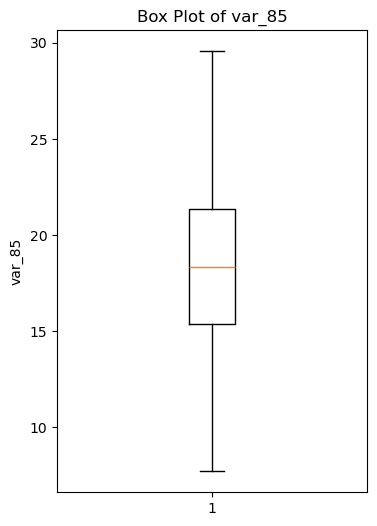

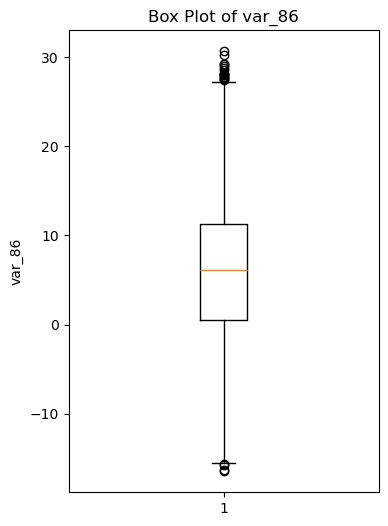

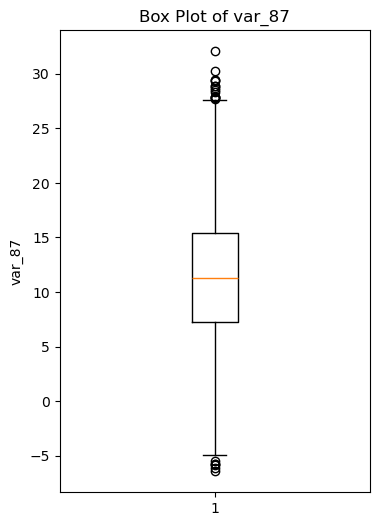

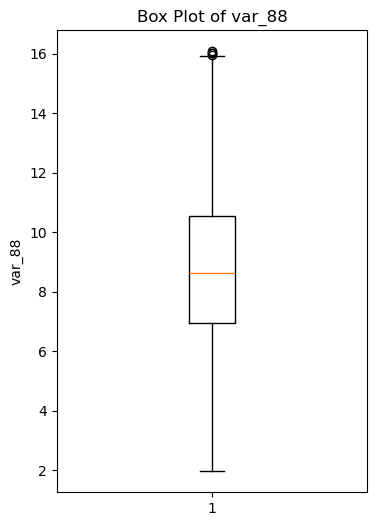

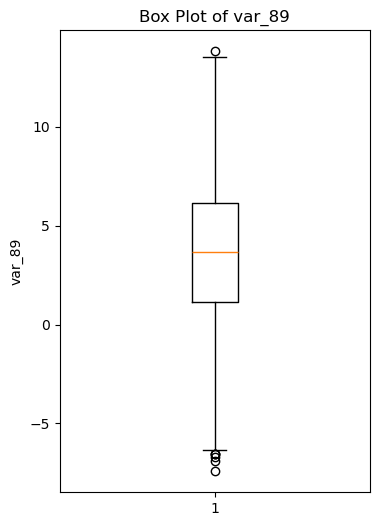

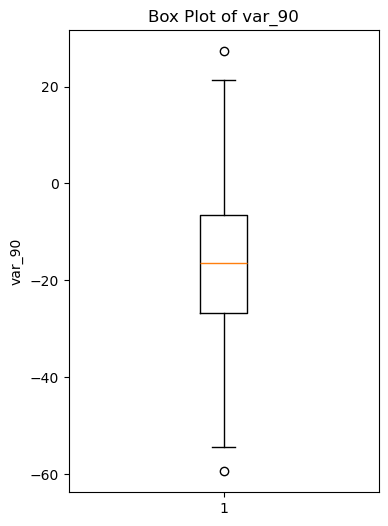

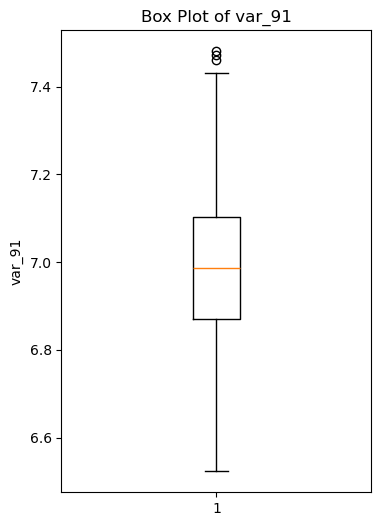

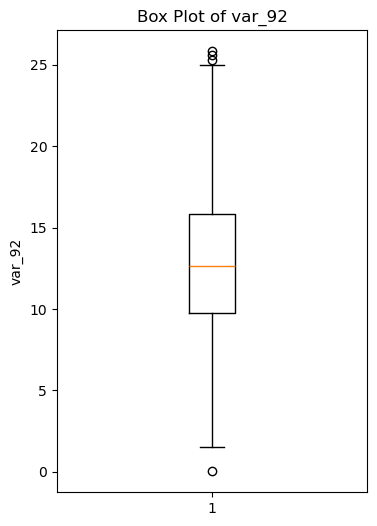

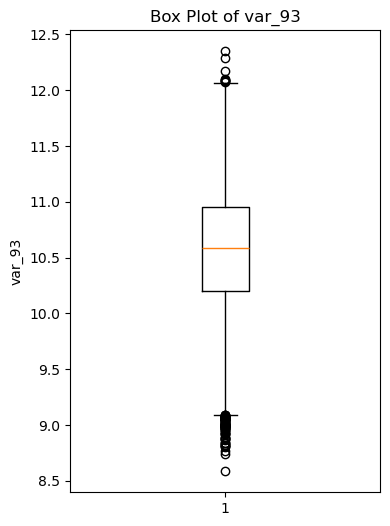

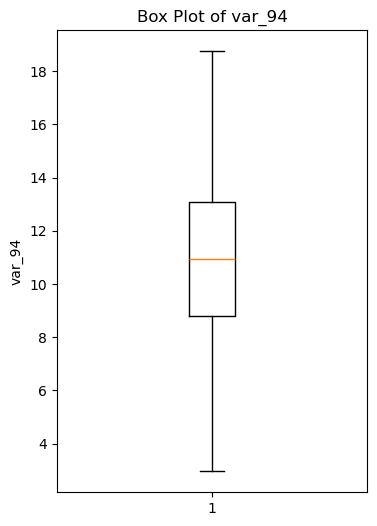

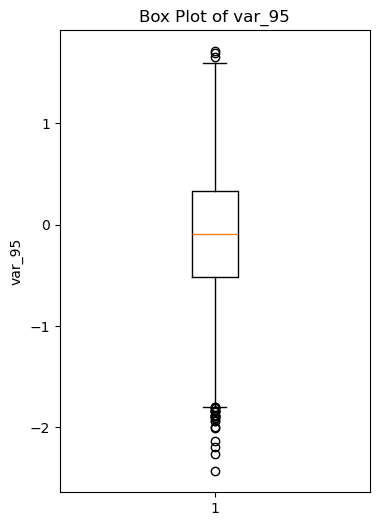

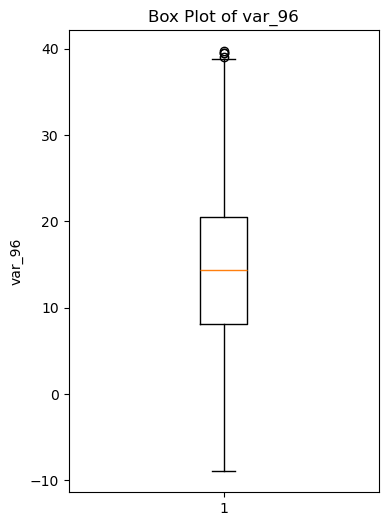

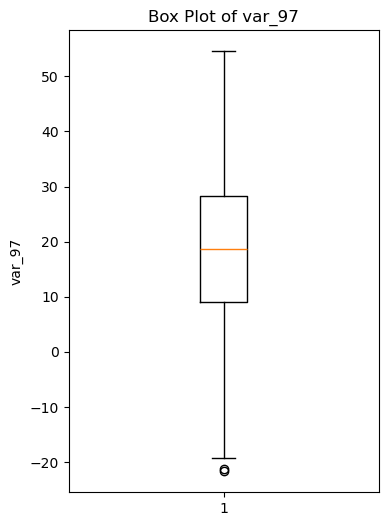

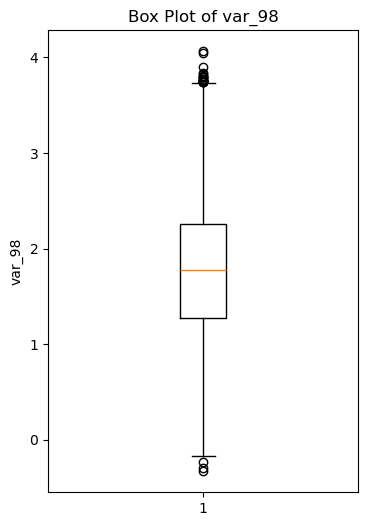

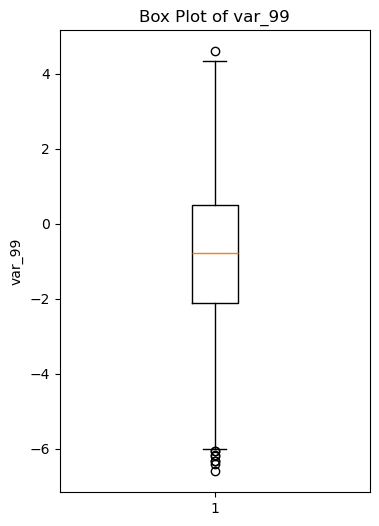

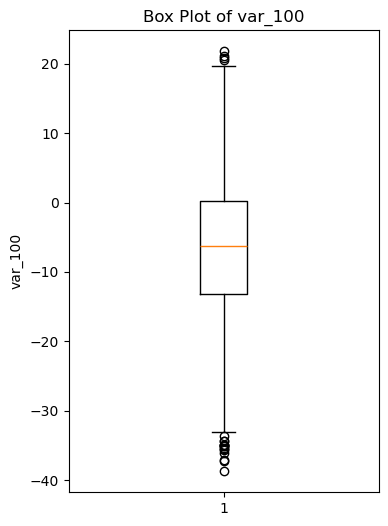

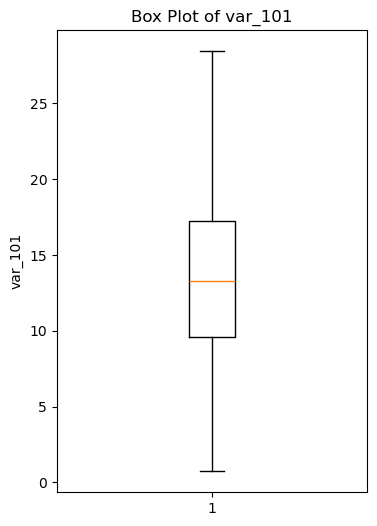

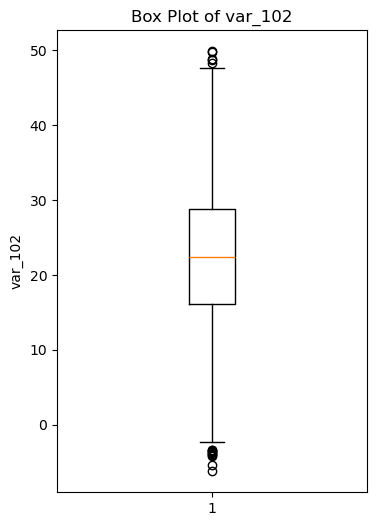

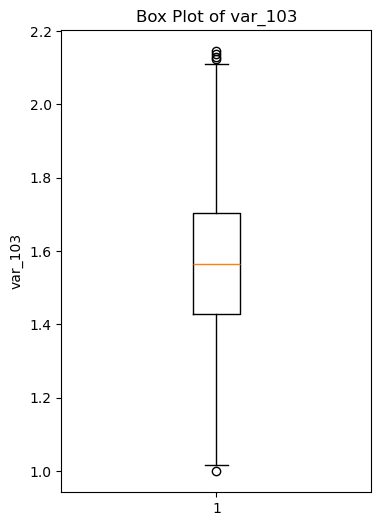

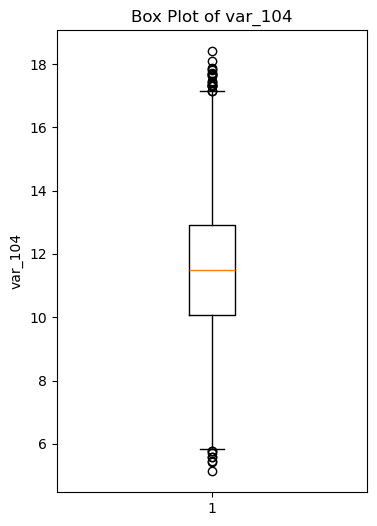

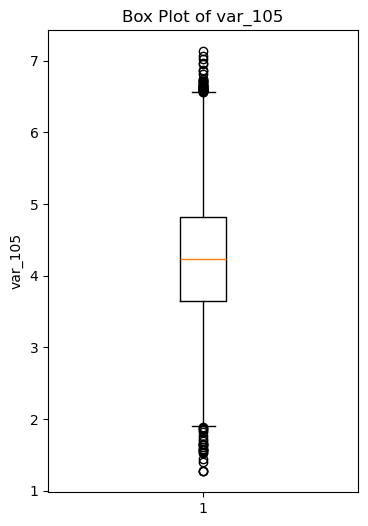

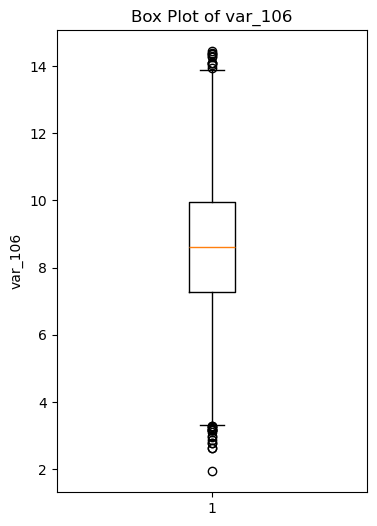

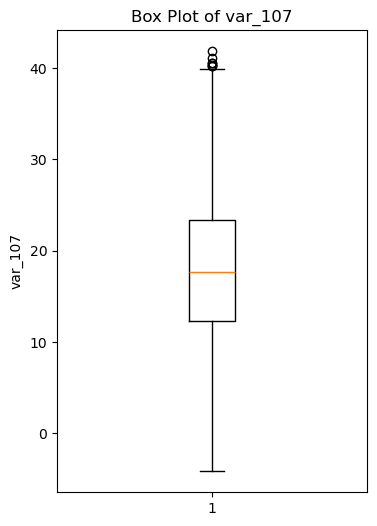

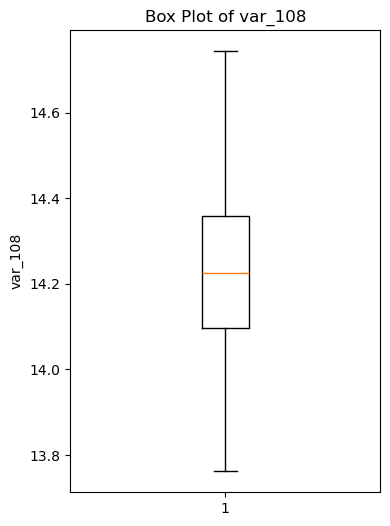

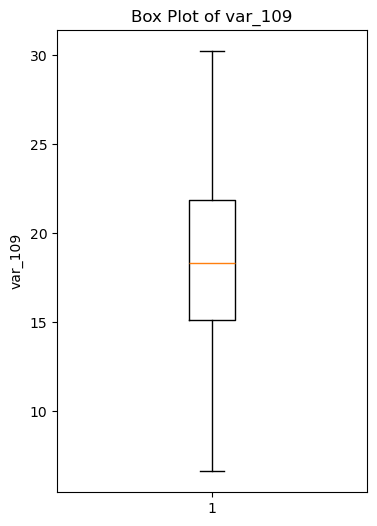

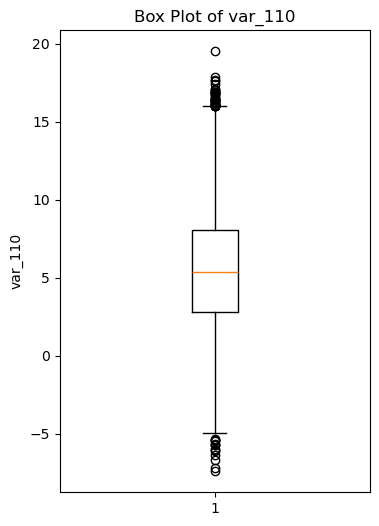

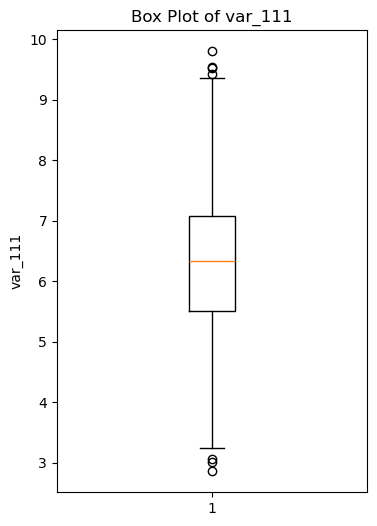

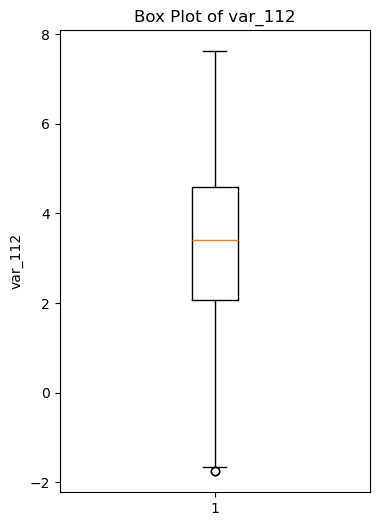

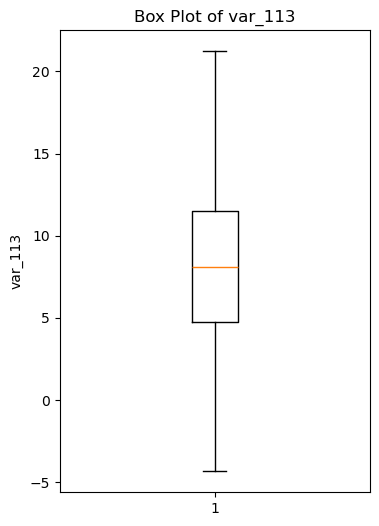

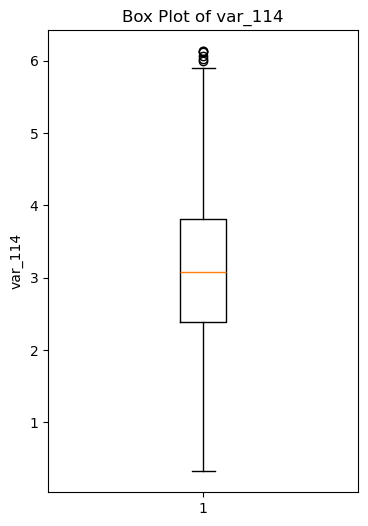

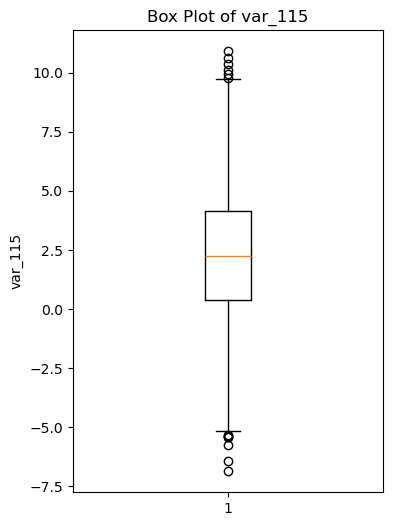

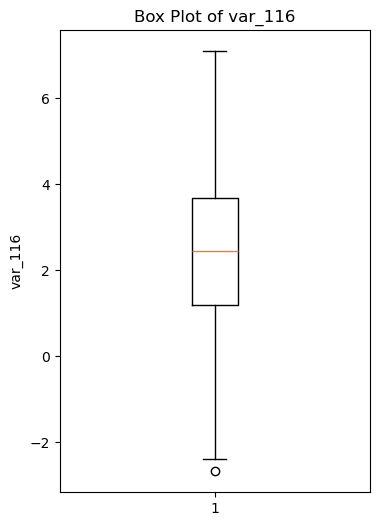

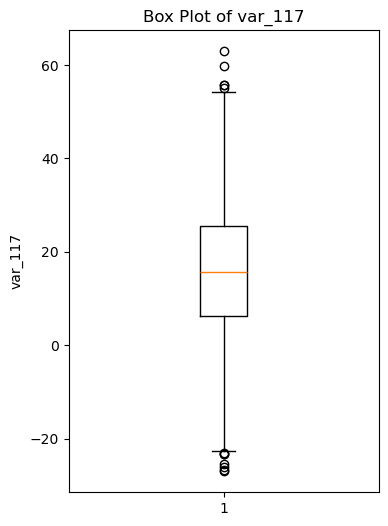

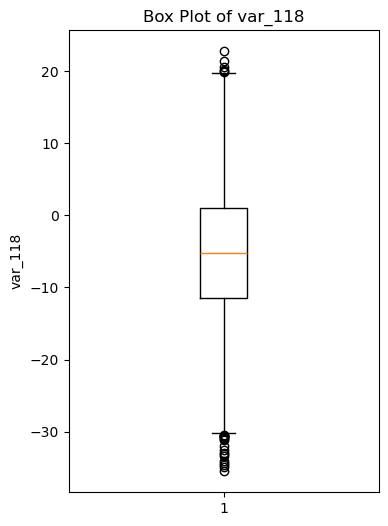

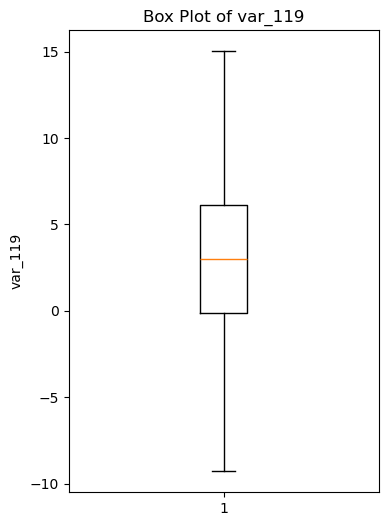

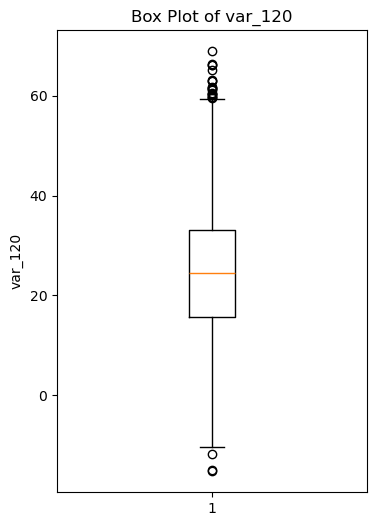

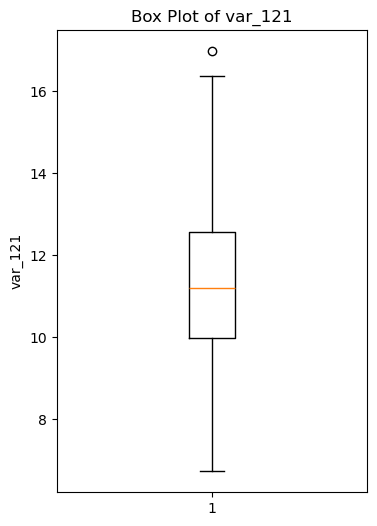

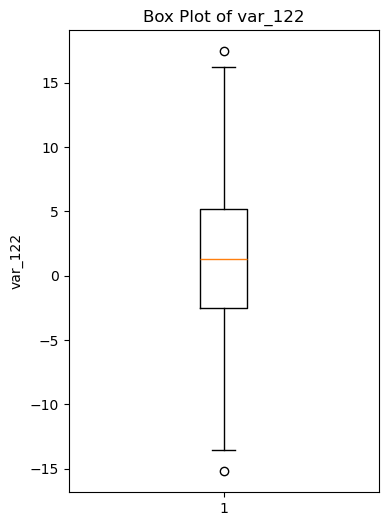

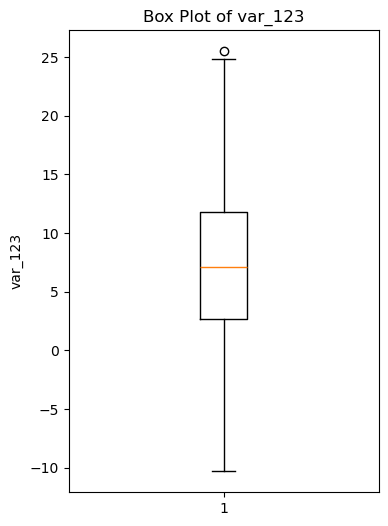

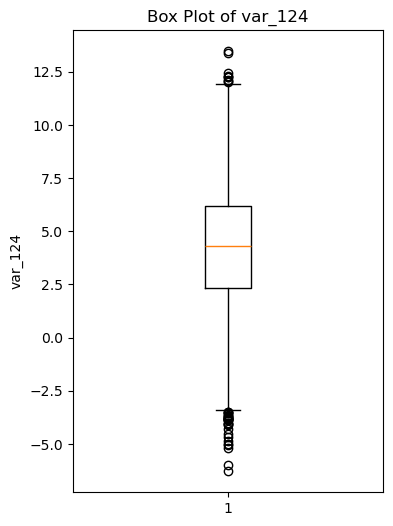

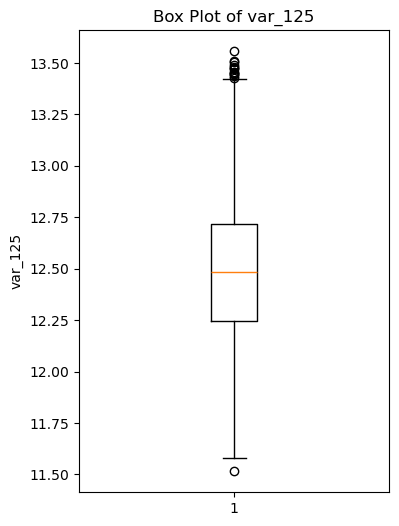

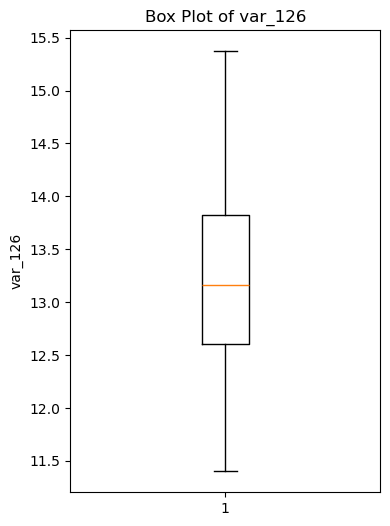

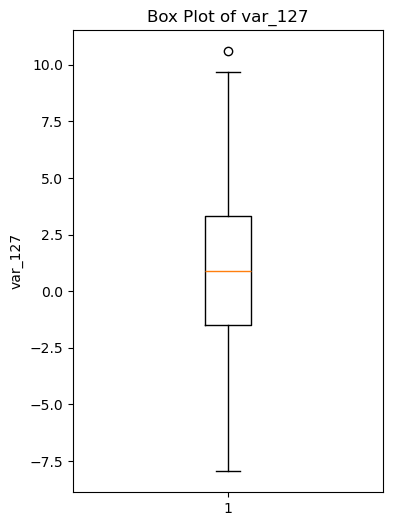

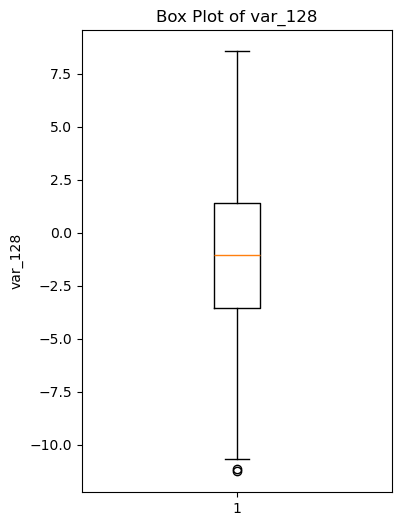

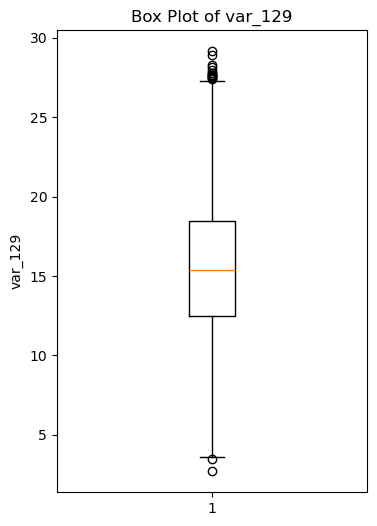

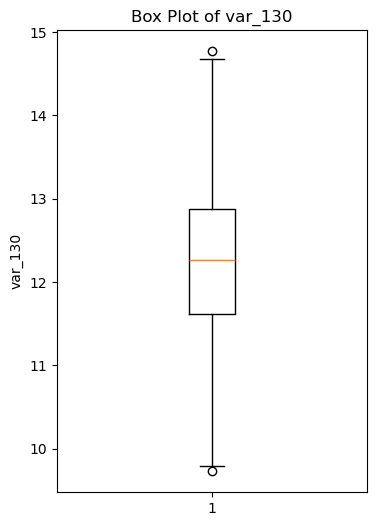

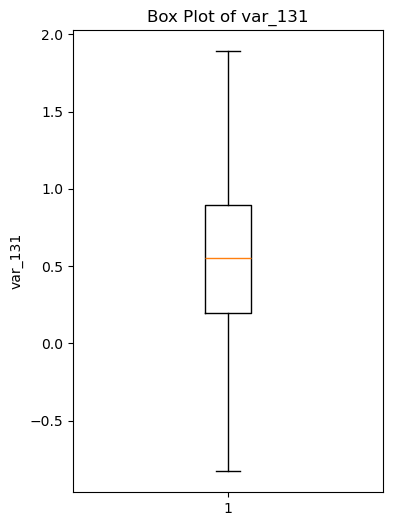

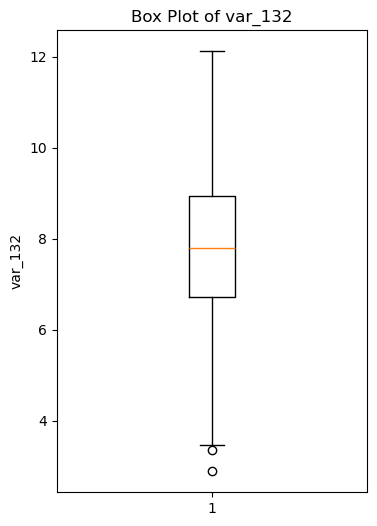

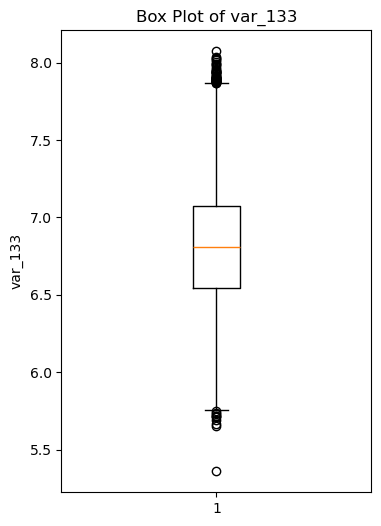

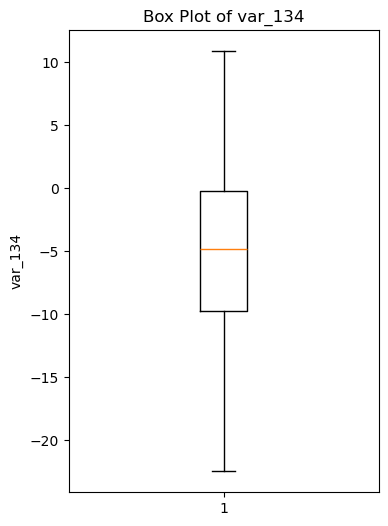

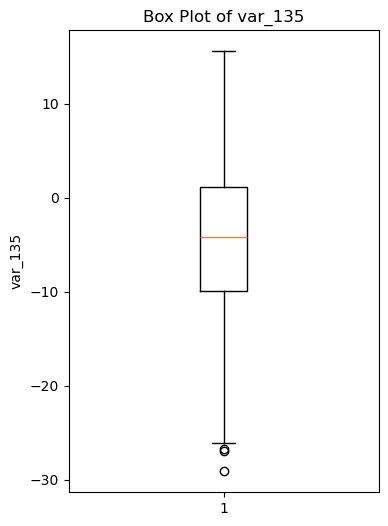

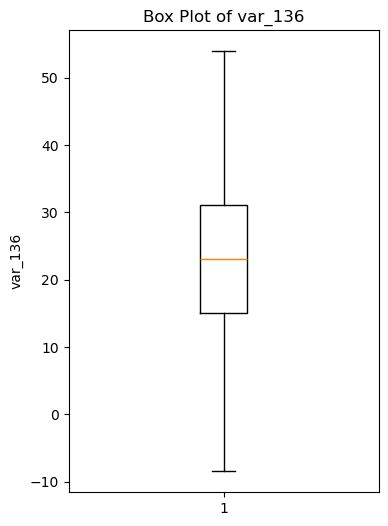

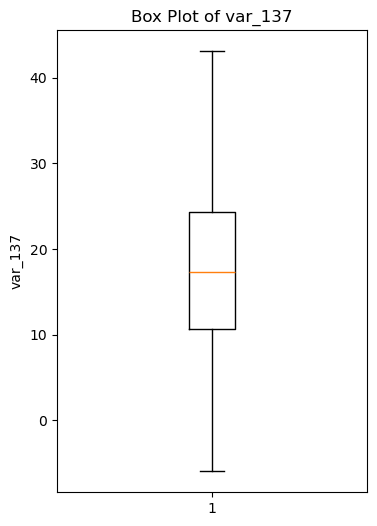

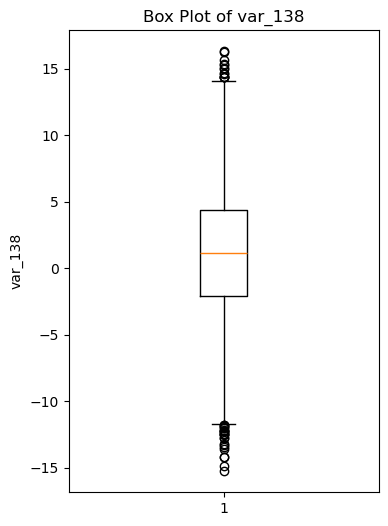

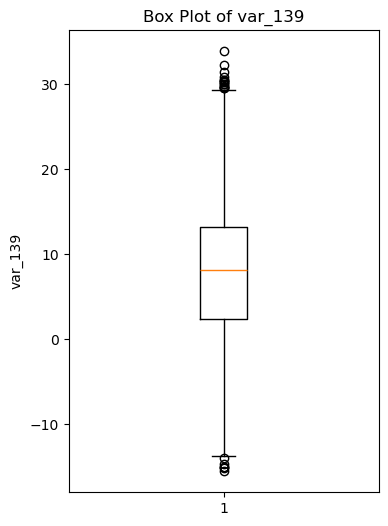

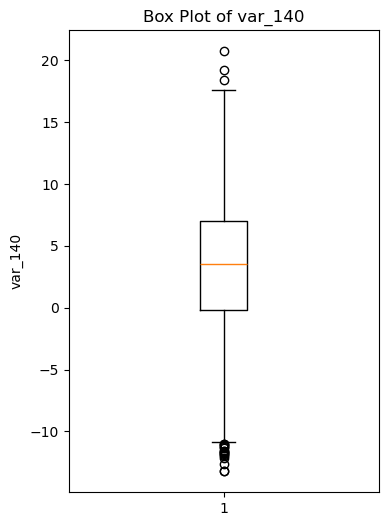

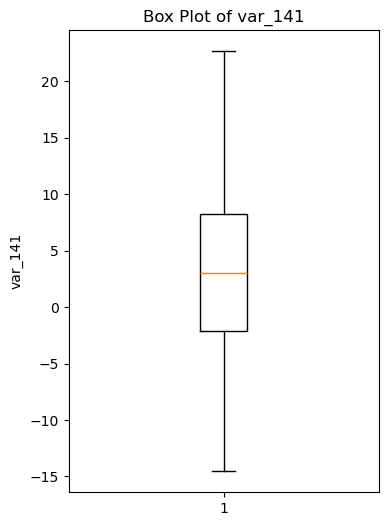

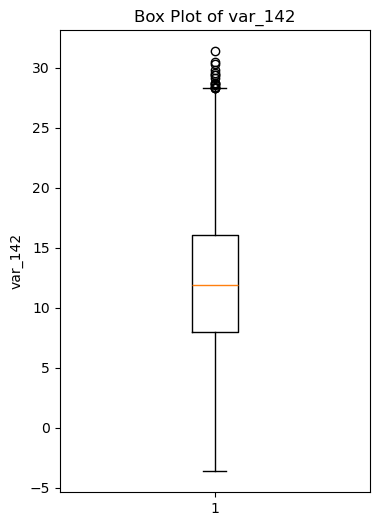

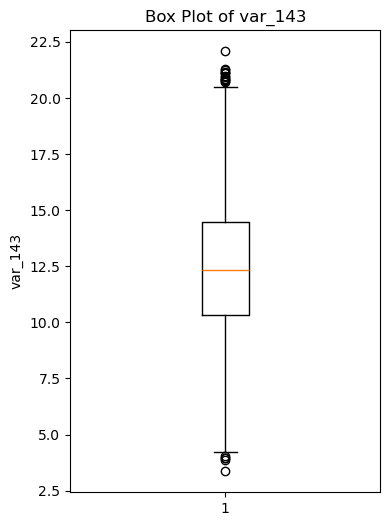

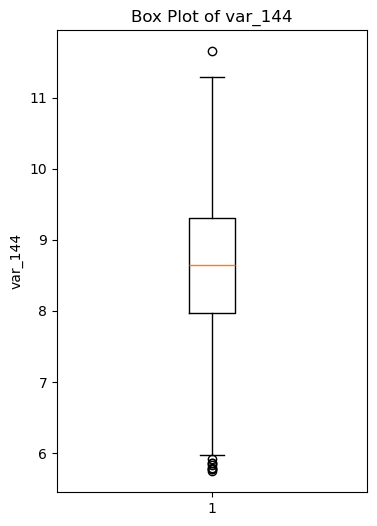

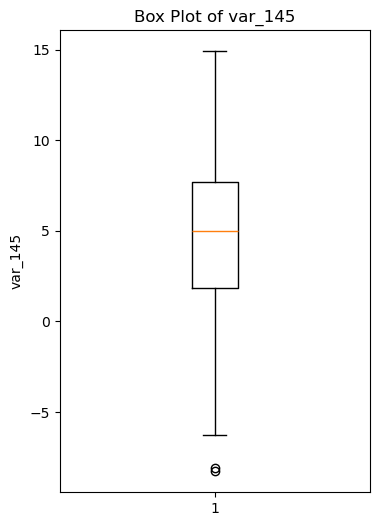

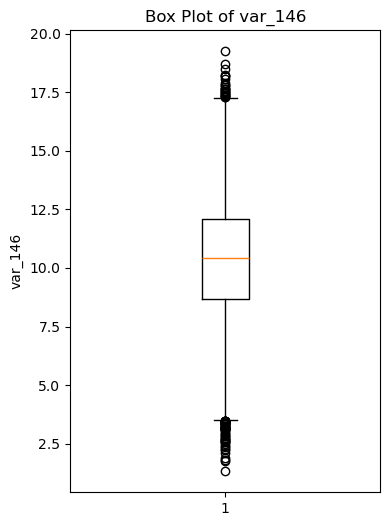

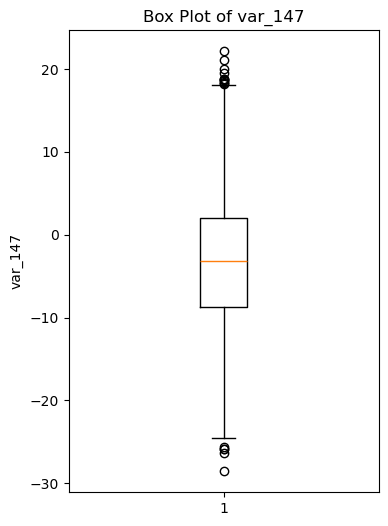

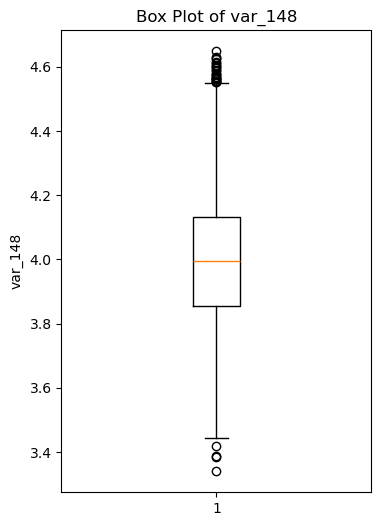

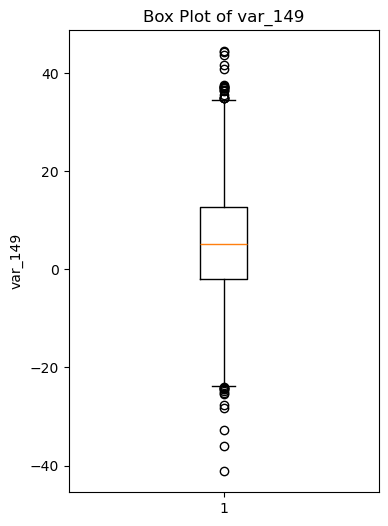

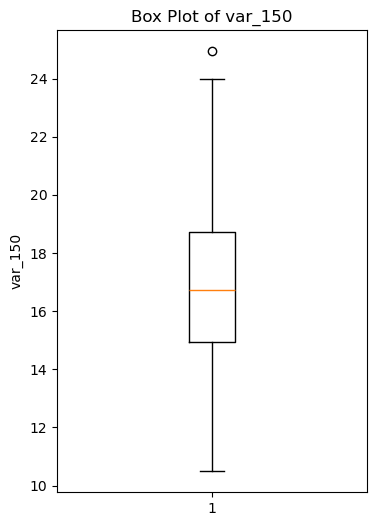

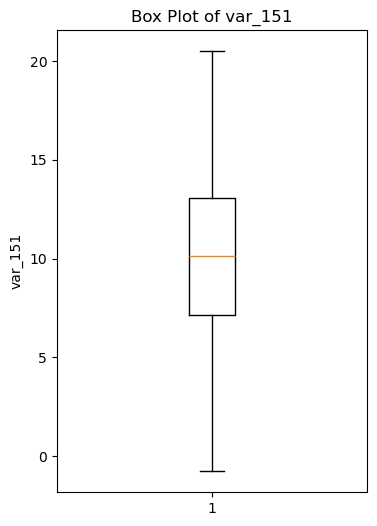

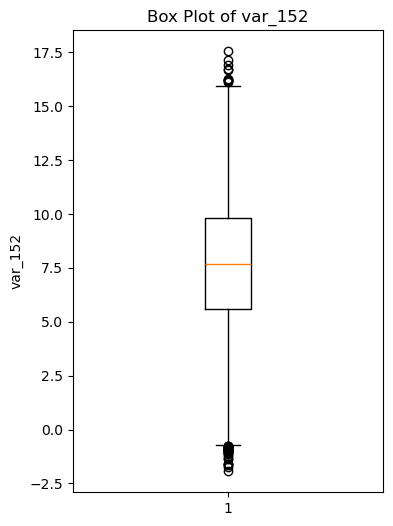

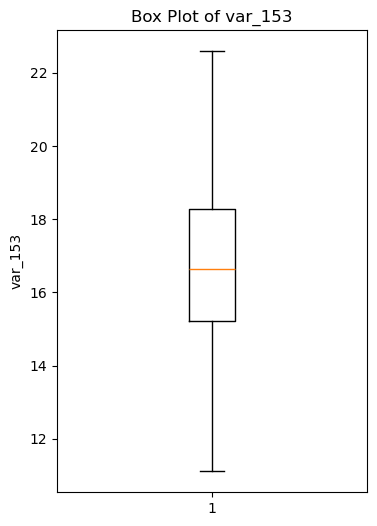

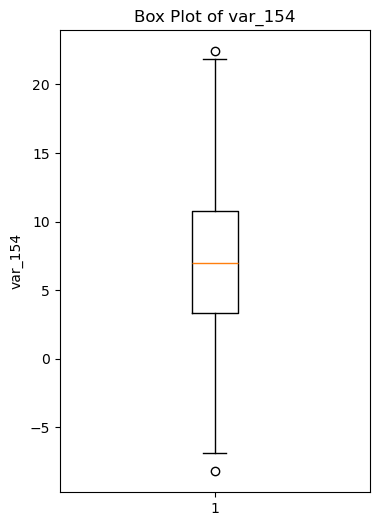

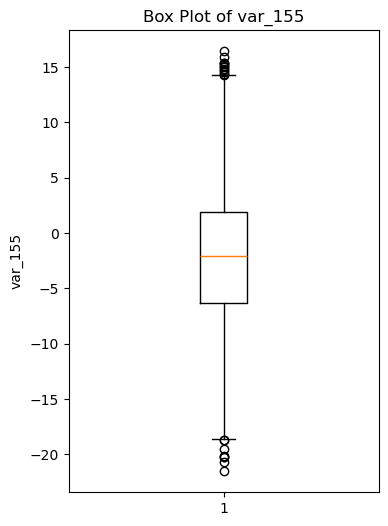

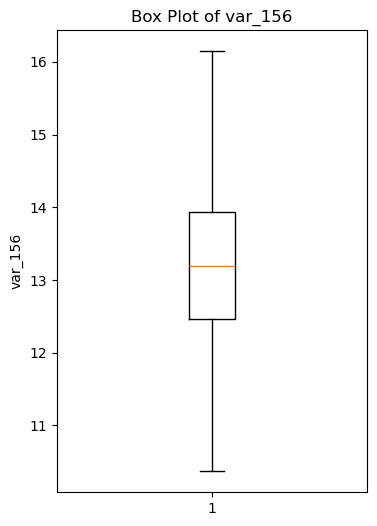

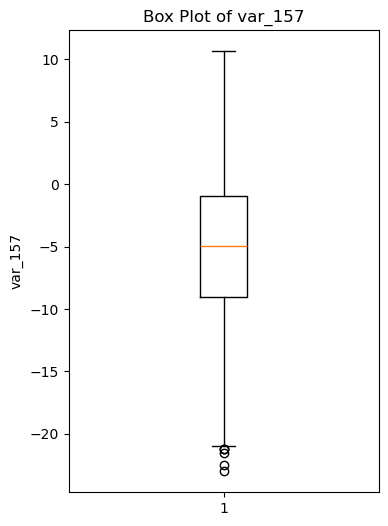

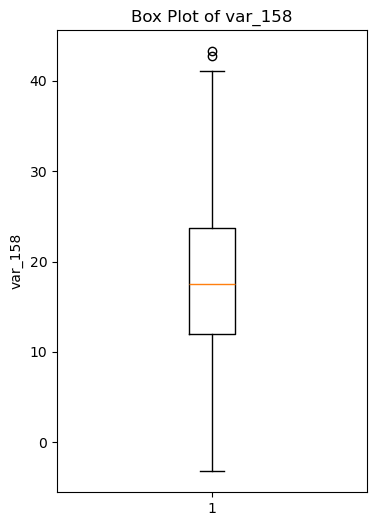

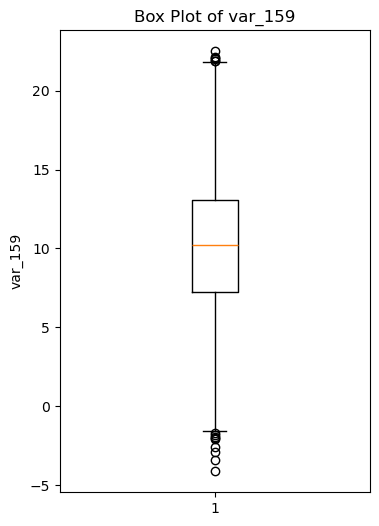

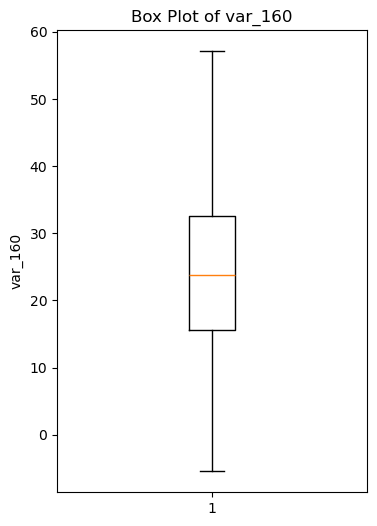

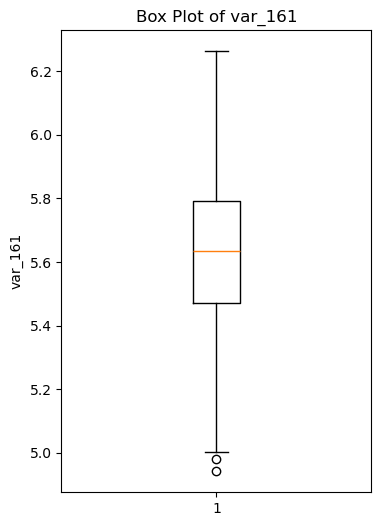

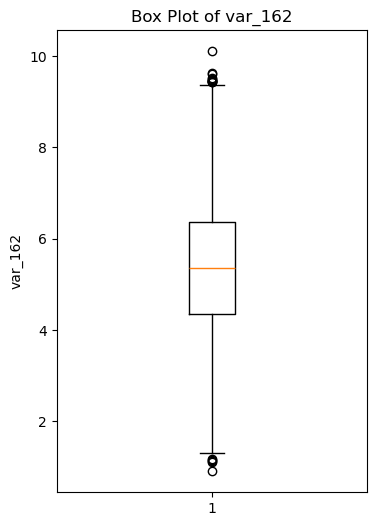

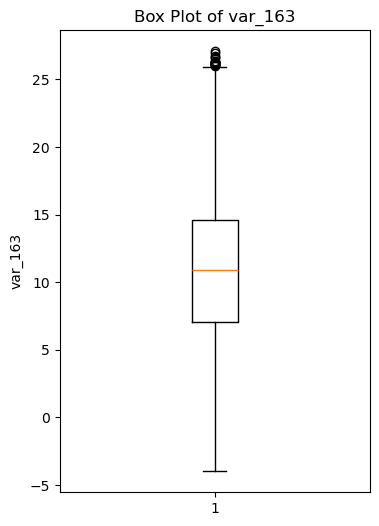

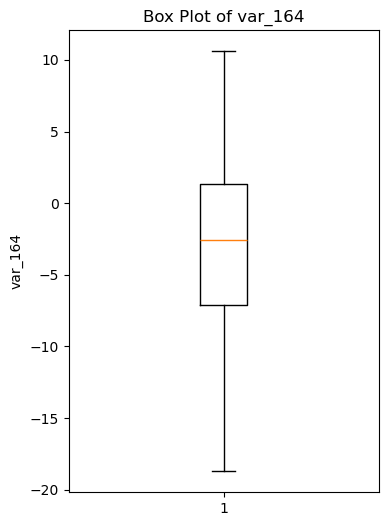

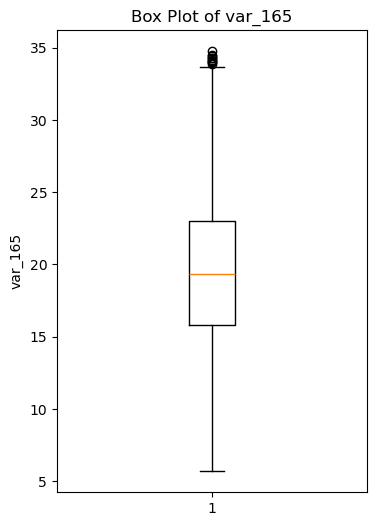

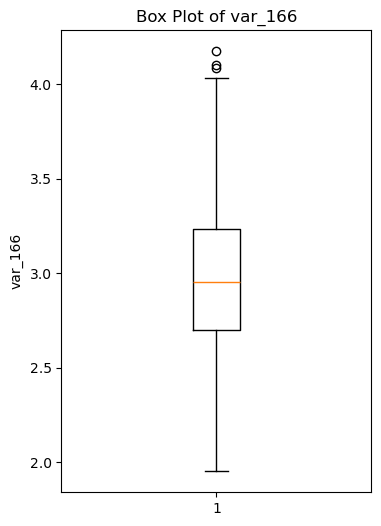

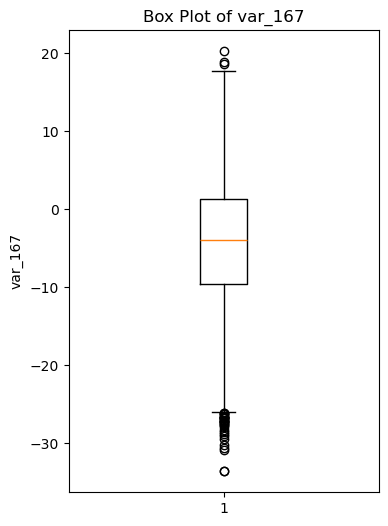

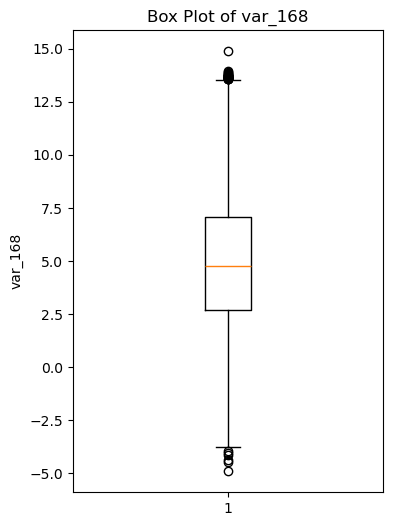

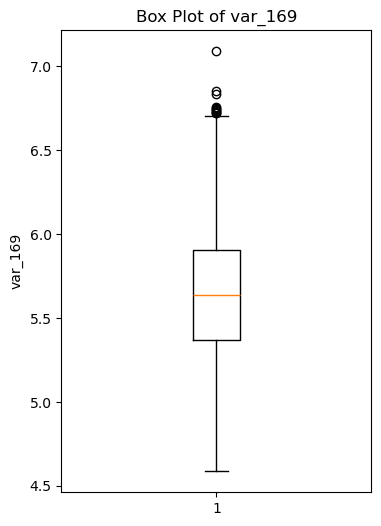

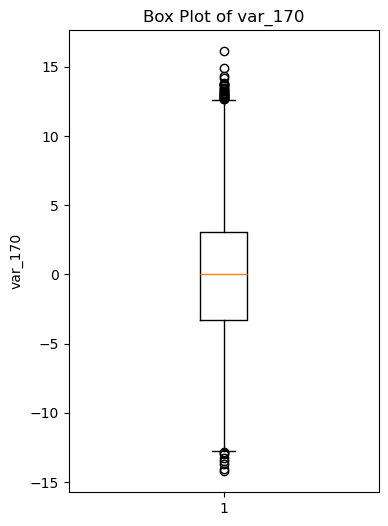

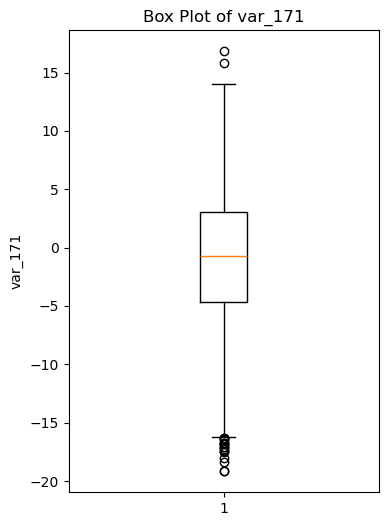

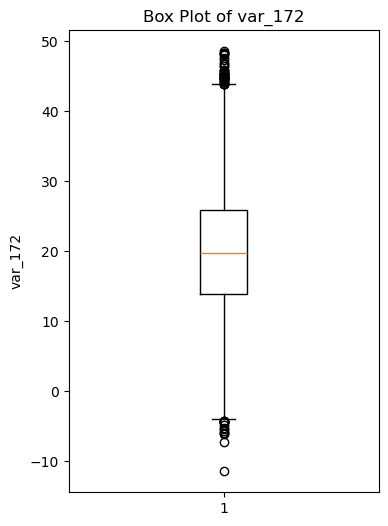

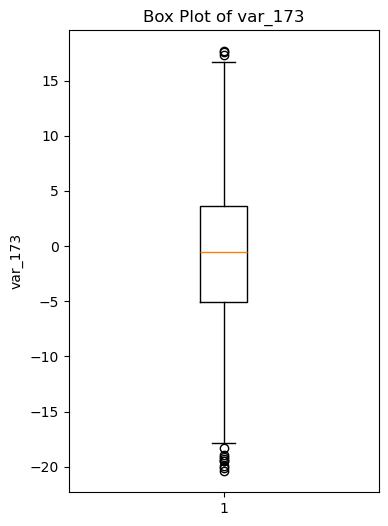

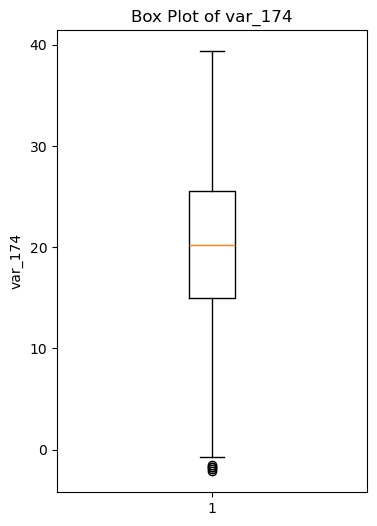

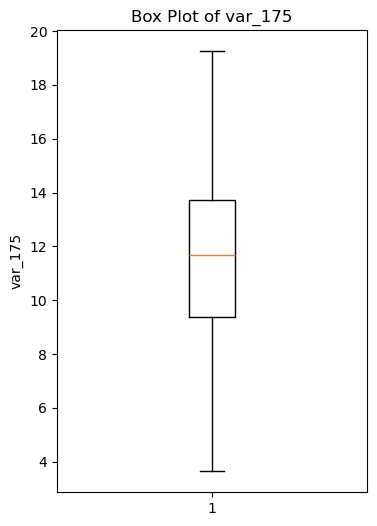

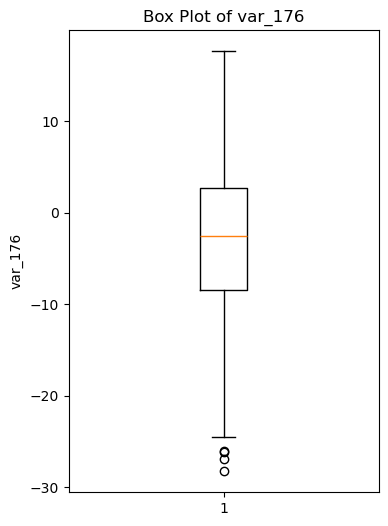

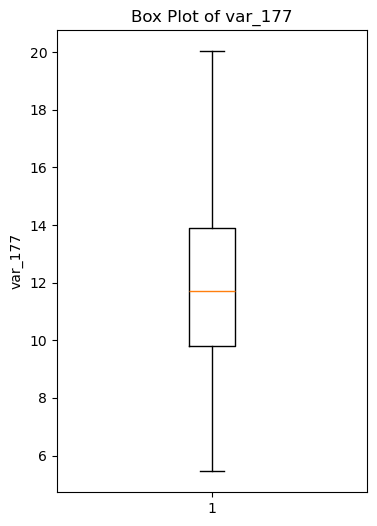

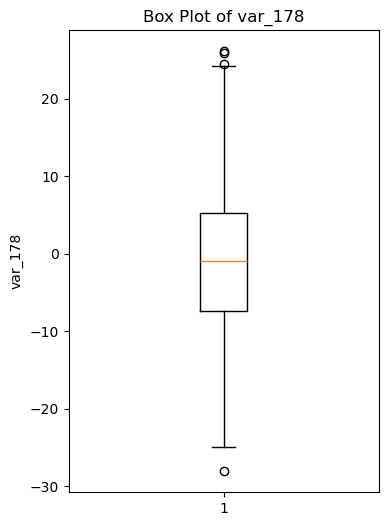

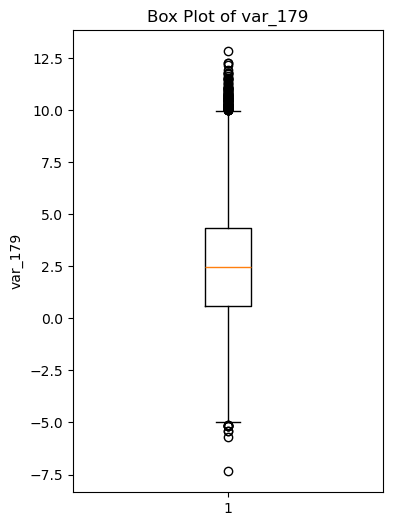

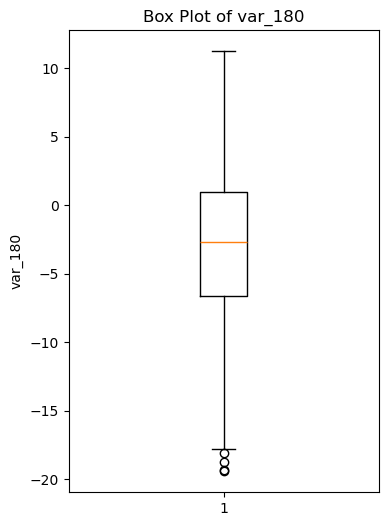

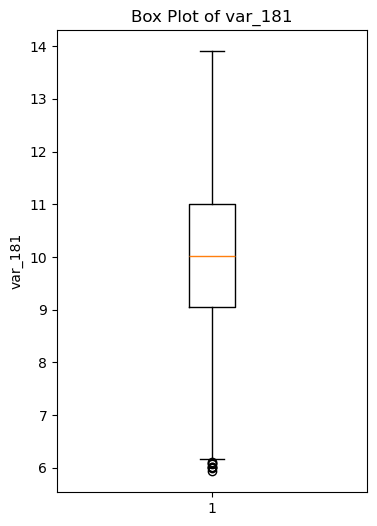

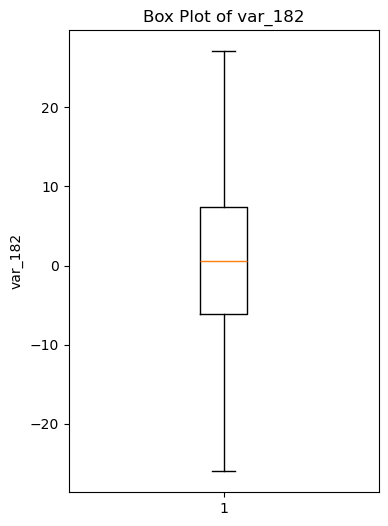

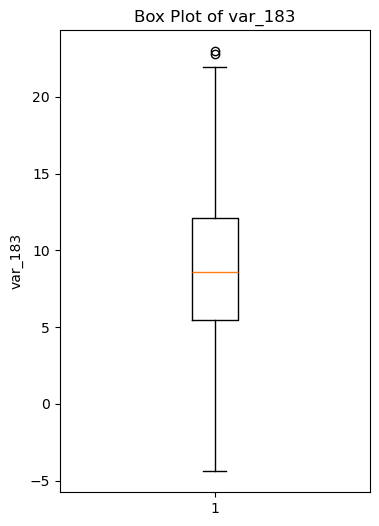

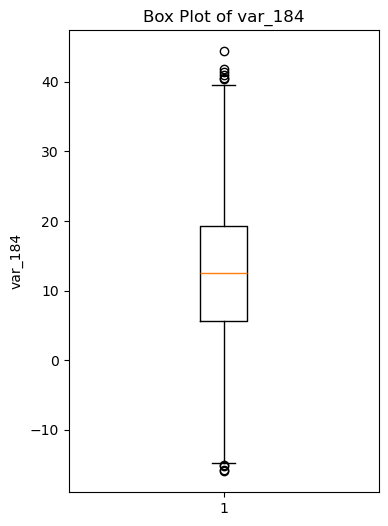

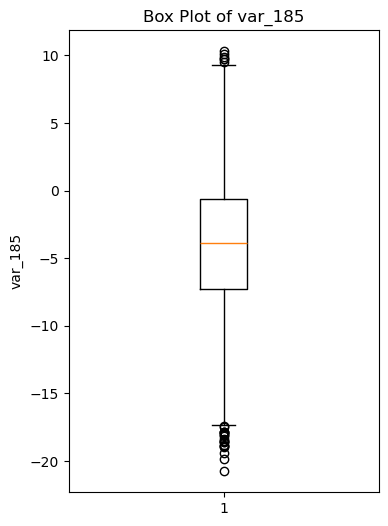

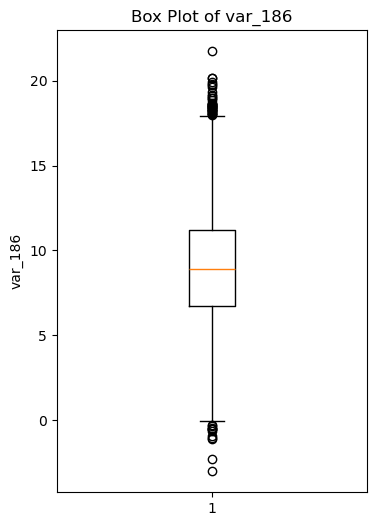

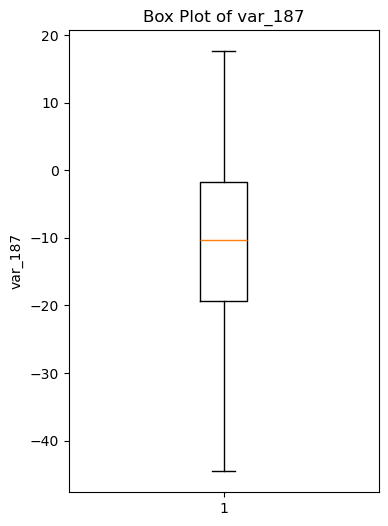

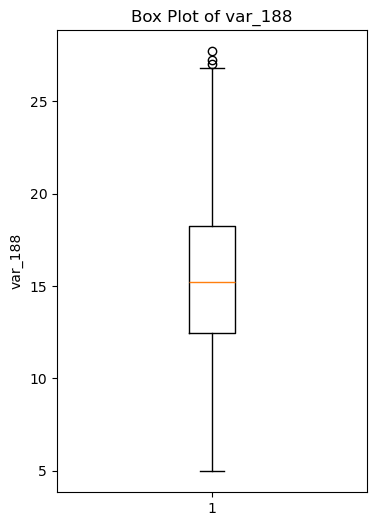

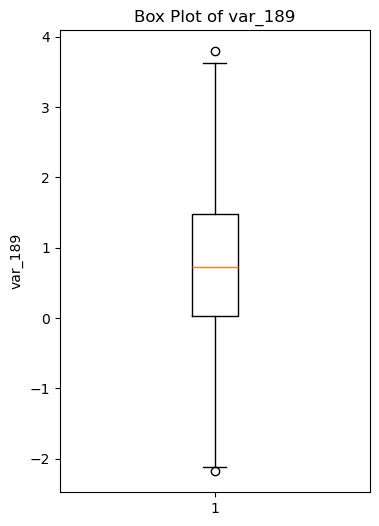

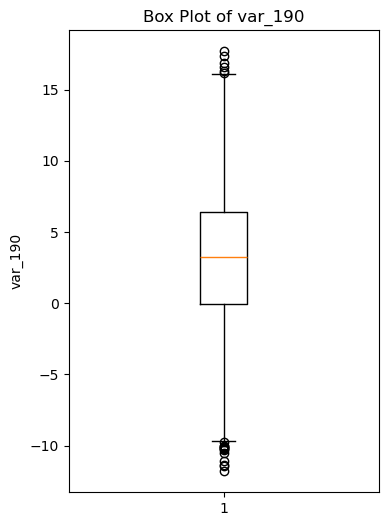

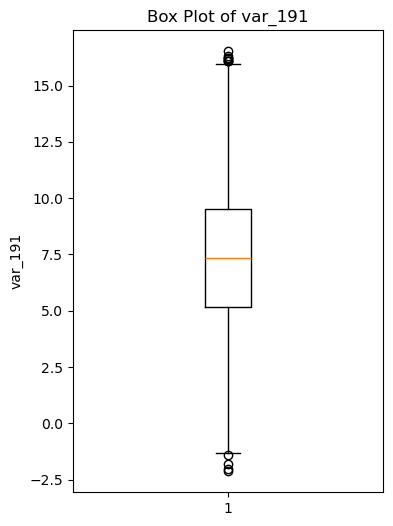

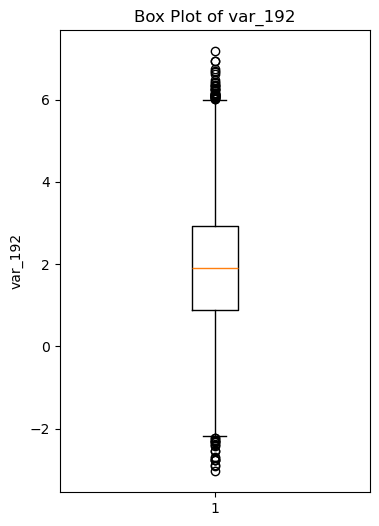

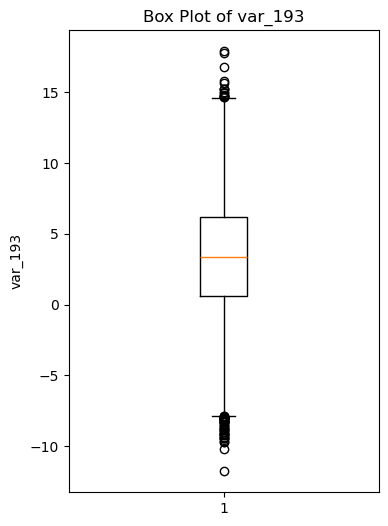

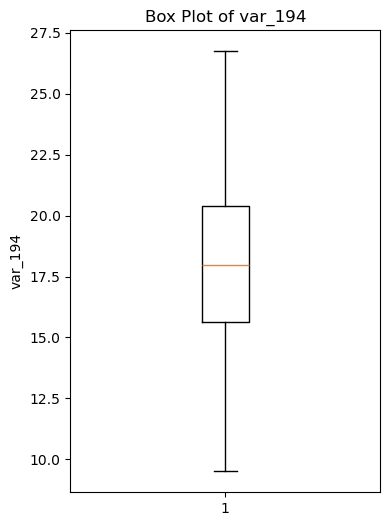

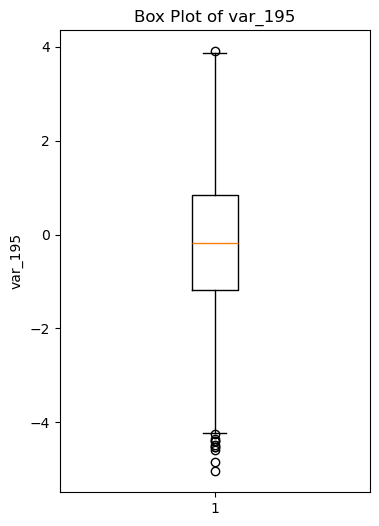

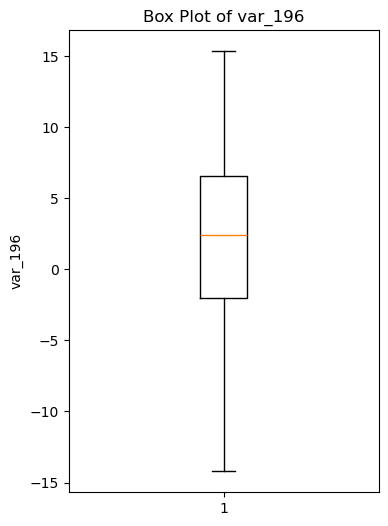

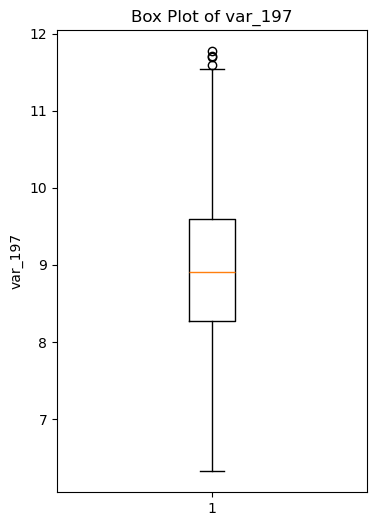

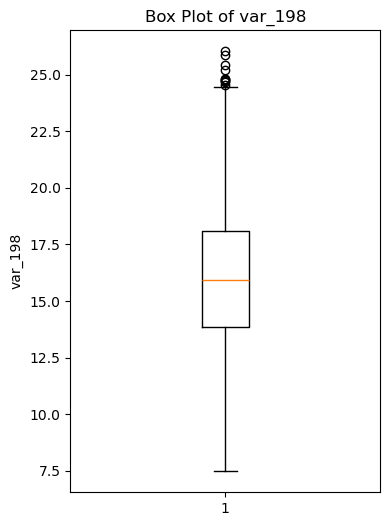

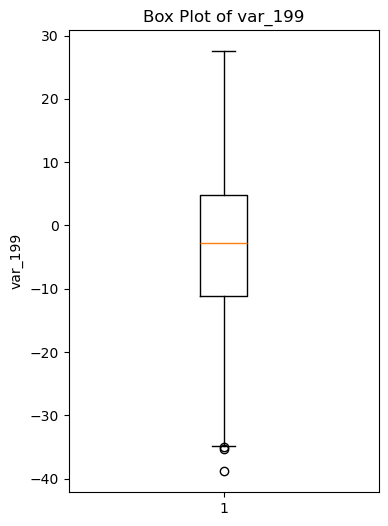

In [27]:
#Excluding id and target, start drawing the boxplot from the third column
cols_to_plot = customer_clean.columns[2:]

print("Variables to plot:", cols_to_plot)

for col in cols_to_plot:
    plt.figure(figsize=(4, 6))
    plt.boxplot(customer_clean[col])
    plt.title(f"Box Plot of {col}")
    plt.ylabel(col)
    plt.show()

In [28]:
# Set random seed
random_seed = 123

# Separate features (X) and target (y)
X = customer_clean.drop(['target', 'ID_code'], axis=1)
y = customer_clean['target']


# Split the dataset into the training set (70%) and test set (30%)
# The training set is the first output, the test set is the second.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state= random_seed,
    stratify= y)

In [29]:
# Find proportion of target classes in the original dataset
print("Original Dataset TARGET Proportions:")
print(customer_clean['target'].value_counts(normalize=True))

# Find proportion of churns in the training set
print("\nTraining Set TARGET Proportions:")
print(y_train.value_counts(normalize=True))


# Find proportion of target classes in the test set
print("\nTest Set TARGET Proportions:")
print(y_test.value_counts(normalize=True))


Original Dataset TARGET Proportions:
target
0    0.9018
1    0.0982
Name: proportion, dtype: float64

Training Set TARGET Proportions:
target
0    0.901786
1    0.098214
Name: proportion, dtype: float64

Test Set TARGET Proportions:
target
0    0.901833
1    0.098167
Name: proportion, dtype: float64


In [30]:
#calculate infomation gain
IG_scores = mutual_info_classif(X_train,y_train,random_state=random_seed)
weights = pd.DataFrame({'attr_importance': IG_scores},index=X_train.columns)
# Sort the weights in decreasing order of information gain values
weights = weights.sort_values('attr_importance', ascending=False)

#make a plot for infomation gain
# Calculate information gain for all features
IG_scores = mutual_info_classif(X_train, y_train, random_state=random_seed)

# Create a DataFrame with the results
weights = pd.DataFrame({'attr_importance': IG_scores}, index=X_train.columns)

# Print weights
print("Information Gain (Mutual Information) Scores:")
print(weights)

Information Gain (Mutual Information) Scores:
         attr_importance
var_0           0.001840
var_1           0.003433
var_2           0.000483
var_3           0.002782
var_4           0.000820
...                  ...
var_195         0.003252
var_196         0.000000
var_197         0.000000
var_198         0.002876
var_199         0.000000

[199 rows x 1 columns]


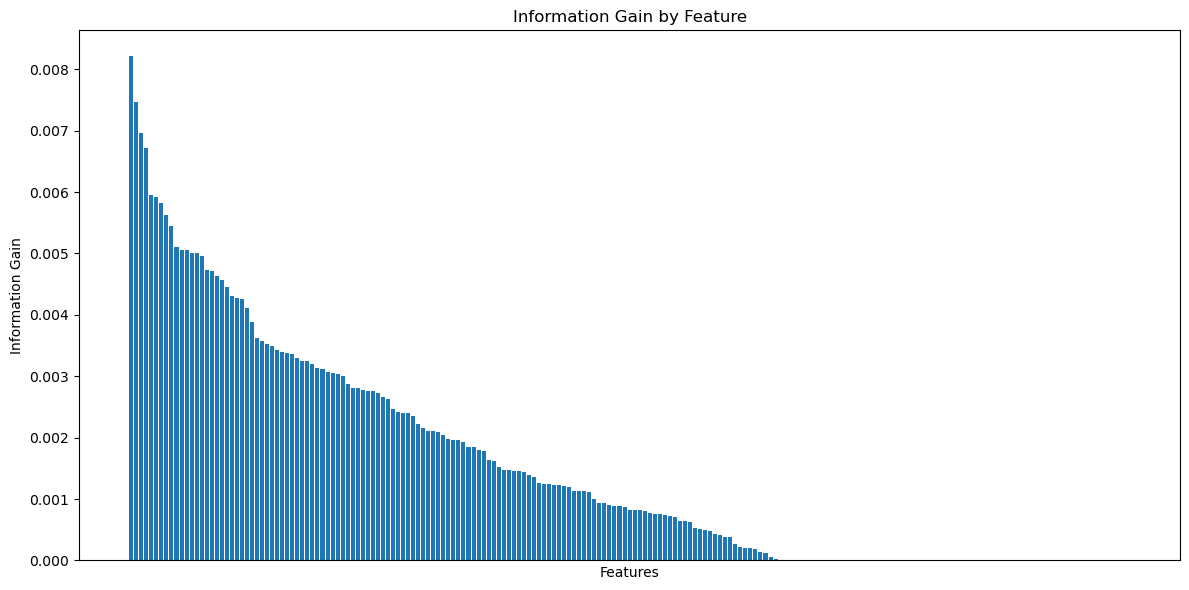

In [31]:
# Plot the weights
weights = weights.sort_values('attr_importance', ascending=False)
plt.figure(figsize=(12, 6))
plt.bar(range(len(weights)), weights['attr_importance'])
plt.xticks(range(len(weights)), weights.index, rotation=90)
plt.xlabel('Features')
plt.ylabel('Information Gain')
plt.title('Information Gain by Feature')
plt.xticks([])
plt.tight_layout()
plt.show()

In [32]:
#Select features with positive importance(attr_importance > 0)
features=weights[weights['attr_importance']>0].index.tolist()
print(len(features))

129


In [33]:
# Subset train and test data to these selected features
X_train_features = X_train[features]
X_test_features = X_test[features]

# Standardize the selected features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_features)
X_test_scaled = scaler.transform(X_test_features)


In [34]:
# Build a logistic regression model and build Logistic Regression with class_weight
LogReg = LogisticRegression(class_weight='balanced',random_state=random_seed,max_iter=5000)
LogReg.fit(X_train_scaled, y_train)

print("Logistic Regression Model trained successfully")
print(f"\nNumber of Iterations: {LogReg.n_iter_}")
print(f"Training accuracy: {LogReg.score(X_train_scaled, y_train):.4f}")

Logistic Regression Model trained successfully

Number of Iterations: [8]
Training accuracy: 0.7734


In [76]:
#find the most efficient C of Logistic regression
param_grid_lr = {'C': [0.01, 0.1, 1]}

grid_search_lr = GridSearchCV(
    LogReg,
    param_grid_lr,
    cv=5,
    scoring='recall',
)

# Fit the grid search
grid_search_lr.fit(X_train_scaled, y_train)

best_C_lr = grid_search_lr.best_params_['C']
print(f"Best C: {best_C_lr}")
print(f"Best CV recall: {grid_search_lr.best_score_:.4f}")
print(pd.DataFrame(grid_search_lr.cv_results_)[['param_C', 'mean_test_score', 'std_test_score']])

Best C: 0.01
Best CV recall: 0.7265
   param_C  mean_test_score  std_test_score
0     0.01         0.726545        0.027056
1     0.10         0.725818        0.027367
2     1.00         0.726545        0.028298


In [77]:
# Predict the class probabilities of the test data
LogReg_prob = LogReg.predict_proba(X_test_scaled)[:, 1]   # Get probabilities for class 1   

LogReg_01 = np.where(LogReg_prob >= 0.1, 1, 0)
LogReg_02 = np.where(LogReg_prob >= 0.2, 1, 0)
LogReg_03 = np.where(LogReg_prob >= 0.3, 1, 0)
LogReg_04 = np.where(LogReg_prob >= 0.4, 1, 0)
LogReg_class = np.where(LogReg_prob >= 0.5, 1, 0) 

# Compute and print the confusion matrix
print("Confusion Matrix - Logistic Regression (default threshold = 0.5):")
print(confusion_matrix(y_test, LogReg_class))
print("\nClassification Report - Logistic Regression (default threshold = 0.5):")
print(classification_report(y_test, LogReg_class))

print("\nConfusion Matrix - Logistic Regression (custom threshold = 0.1):")
print(confusion_matrix(y_test, LogReg_01))
print("\nClassification Report - Logistic Regression (custom threshold = 0.1):")
print(classification_report(y_test, LogReg_01))

print("\nConfusion Matrix - Logistic Regression (custom threshold = 0.2):")
print(confusion_matrix(y_test, LogReg_02))
print("\nClassification Report - Logistic Regression (custom threshold = 0.2):")
print(classification_report(y_test, LogReg_02))

print("\nConfusion Matrix - Logistic Regression (custom threshold = 0.3):")
print(confusion_matrix(y_test, LogReg_03))
print("\nClassification Report - Logistic Regression (custom threshold = 0.3):")
print(classification_report(y_test, LogReg_03))

print("\nConfusion Matrix - Logistic Regression (custom threshold = 0.4):")
print(confusion_matrix(y_test, LogReg_04))
print("\nClassification Report - Logistic Regression (custom threshold = 0.4):")
print(classification_report(y_test, LogReg_04))

# Calculate specific metrics
LogReg_final_pred = LogReg_01
LogReg_final_threshold = 0.1

accuracy_logreg = accuracy_score(y_test, LogReg_class)
precision_logreg = precision_score(y_test, LogReg_class)
recall_logreg = recall_score(y_test, LogReg_class)
f1_logreg = f1_score(y_test, LogReg_class)

print(f"\nMetrics for Logistic Regression: (threshold = {LogReg_final_threshold})")
print(f"Accuracy: {accuracy_logreg:.4f}")
print(f"Precision: {precision_logreg:.4f}")
print(f"Recall (Sensitivity): {recall_logreg:.4f}")
print(f"F1-Score: {f1_logreg:.4f}")

Confusion Matrix - Logistic Regression (default threshold = 0.5):
[[4137 1274]
 [ 158  431]]

Classification Report - Logistic Regression (default threshold = 0.5):
              precision    recall  f1-score   support

           0       0.96      0.76      0.85      5411
           1       0.25      0.73      0.38       589

    accuracy                           0.76      6000
   macro avg       0.61      0.75      0.61      6000
weighted avg       0.89      0.76      0.81      6000


Confusion Matrix - Logistic Regression (custom threshold = 0.1):
[[1248 4163]
 [  16  573]]

Classification Report - Logistic Regression (custom threshold = 0.1):
              precision    recall  f1-score   support

           0       0.99      0.23      0.37      5411
           1       0.12      0.97      0.22       589

    accuracy                           0.30      6000
   macro avg       0.55      0.60      0.29      6000
weighted avg       0.90      0.30      0.36      6000


Confusion Matrix

In [36]:
param_grid_svm = {'C': [0.01, 0.1, 1]}

# Create GridSearchCV object
grid_search_svm = GridSearchCV(
    SVC(kernel='rbf', class_weight='balanced',random_state=random_seed, probability=True),
    param_grid_svm,
    cv=5,  
    scoring='recall',
)

# Fit the grid search
grid_search_svm.fit(X_train_scaled, y_train)

# Get the best model
svm_best = grid_search_svm.best_estimator_

best_svm = grid_search_svm.best_params_['C']
print(f"Best C: {best_svm}")
print(f"Best CV recall: {grid_search_svm.best_score_:.4f}")
print(pd.DataFrame(grid_search_svm.cv_results_)[['param_C', 'mean_test_score', 'std_test_score']])

Best C: 0.01
Best CV recall: 0.9913
   param_C  mean_test_score  std_test_score
0     0.01         0.991273        0.006744
1     0.10         0.728000        0.017725
2     1.00         0.410909        0.015081


In [57]:
# Build SVM model with probability=True
SVM_model = SVC(kernel='rbf', C=1.0, class_weight='balanced',random_state=random_seed, probability=True)
SVM_model.fit(X_train_scaled, y_train)

print("SVM Model trained successfully")
print(f"Training accuracy: {SVM_model.score(X_train_scaled, y_train):.4f}")

SVM Model trained successfully
Training accuracy: 0.9827


In [78]:
SVM_prob = SVM_model.predict_proba(X_test_scaled)[:, 1]
# Predict the class of the test data
SVM_pred_01 = np.where(SVM_prob >= 0.1, 1, 0)
SVM_pred_02 = np.where(SVM_prob >= 0.2, 1, 0)
SVM_pred_03 = np.where(SVM_prob >= 0.3, 1, 0)
SVM_pred_04 = np.where(SVM_prob >= 0.4, 1, 0)
SVM_pred = SVM_model.predict(X_test_scaled)

# Compute confusion matrix
print("Confusion Matrix - SVM (default threshold):")
print(confusion_matrix(y_test, SVM_pred))
print("\nClassification Report - SVM (default threshold):")
print(classification_report(y_test, SVM_pred, zero_division=0))

print("\nConfusion Matrix - SVM (custom threshold = 0.1):")
print(confusion_matrix(y_test, SVM_pred_01))
print("\nClassification Report - SVM (custom threshold = 0.1):")
print(classification_report(y_test, SVM_pred_01, zero_division=0))

print("\nConfusion Matrix - SVM (custom threshold = 0.2):")
print(confusion_matrix(y_test, SVM_pred_02))
print("\nClassification Report - SVM (custom threshold = 0.2):")
print(classification_report(y_test, SVM_pred_02, zero_division=0))

print("\nConfusion Matrix - SVM (custom threshold = 0.3):")
print(confusion_matrix(y_test, SVM_pred_03))
print("\nClassification Report - SVM (custom threshold = 0.3):")
print(classification_report(y_test, SVM_pred_03, zero_division=0))

print("\nConfusion Matrix - SVM (custom threshold = 0.4):")
print(confusion_matrix(y_test, SVM_pred_04))
print("\nClassification Report - SVM (custom threshold = 0.4):")
print(classification_report(y_test, SVM_pred_04, zero_division=0))

# Calculate specific metrics
SVM_final_pred = SVM_pred_01
SVM_final_threshold = 0.1

accuracy_svm = accuracy_score(y_test, SVM_final_pred)
precision_svm = precision_score(y_test, SVM_final_pred)
recall_svm = recall_score(y_test, SVM_final_pred)
f1_svm = f1_score(y_test, SVM_final_pred)

print(f"\nMetrics for SVM(threshold = {SVM_final_threshold}):")
print(f"Accuracy: {accuracy_svm:.4f}")
print(f"Precision: {precision_svm:.4f}")
print(f"Recall (Sensitivity): {recall_svm:.4f}")
print(f"F1-Score: {f1_svm:.4f}")

Confusion Matrix - SVM (default threshold):
[[5092  319]
 [ 340  249]]

Classification Report - SVM (default threshold):
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      5411
           1       0.44      0.42      0.43       589

    accuracy                           0.89      6000
   macro avg       0.69      0.68      0.68      6000
weighted avg       0.89      0.89      0.89      6000


Confusion Matrix - SVM (custom threshold = 0.1):
[[4097 1314]
 [ 156  433]]

Classification Report - SVM (custom threshold = 0.1):
              precision    recall  f1-score   support

           0       0.96      0.76      0.85      5411
           1       0.25      0.74      0.37       589

    accuracy                           0.76      6000
   macro avg       0.61      0.75      0.61      6000
weighted avg       0.89      0.76      0.80      6000


Confusion Matrix - SVM (custom threshold = 0.2):
[[4824  587]
 [ 266  323]]

Classification 

In [39]:
# Build Random Forest model
from sklearn.ensemble import RandomForestClassifier

RF_model = RandomForestClassifier(n_estimators=200,class_weight='balanced', random_state=random_seed)
RF_model.fit(X_train_features, y_train)

print("Random Forest Model trained successfully")
print(f"Training accuracy: {RF_model.score(X_train_features, y_train):.4f}")

Random Forest Model trained successfully
Training accuracy: 1.0000


In [40]:
# Predict the class of the test data
RF_prob = RF_model.predict_proba(X_test_features)[:, 1]

RF_pred_01 = np.where(RF_prob >= 0.1, 1, 0)
RF_pred_02 = np.where(RF_prob >= 0.2, 1, 0)
RF_pred_03 = np.where(RF_prob >= 0.3, 1, 0)
RF_pred_04 = np.where(RF_prob >= 0.4, 1, 0)
RF_pred = RF_model.predict(X_test_features)


# Confusion matrix

print("\nConfusion Matrix - Random Forest (custom threshold = 0.1):")
print(confusion_matrix(y_test, RF_pred_01))
print("\nClassification Report - Random Forest (custom threshold = 0.1):")
print(classification_report(y_test, RF_pred_01, zero_division=0))

print("\nConfusion Matrix - Random Forest (custom threshold = 0.2):")
print(confusion_matrix(y_test, RF_pred_02))
print("\nClassification Report - Random Forest (custom threshold = 0.2):")
print(classification_report(y_test, RF_pred_02, zero_division=0))

print("\nConfusion Matrix - Random Forest (custom threshold = 0.3):")
print(confusion_matrix(y_test, RF_pred_03))
print("\nClassification Report - Random Forest (custom threshold = 0.3):")
print(classification_report(y_test, RF_pred_03, zero_division=0))

print("Confusion Matrix - Random Forest (custom threshold = 0.4):")
print(confusion_matrix(y_test, RF_pred_04))
print("\nClassification Report - Random Forest (custom threshold = 0.4):")
print(classification_report(y_test, RF_pred_04, zero_division=0))

print("Confusion Matrix - Random Forest (default threshold = 0.5):")
print(confusion_matrix(y_test, RF_pred))
print("\nClassification Report - Random Forest (default threshold = 0.5):")
print(classification_report(y_test, RF_pred, zero_division=0))

# Calculate best metrics
RF_final_pred = RF_pred_01
rf_final_threshold = 0.1

accuracy_rf = accuracy_score(y_test, RF_final_pred)
precision_rf = precision_score(y_test, RF_final_pred)
recall_rf = recall_score(y_test, RF_final_pred)
f1_rf = f1_score(y_test, RF_final_pred)

print(f"\nMetrics for Random Forest (threshold = {rf_final_threshold}):")
print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall (Sensitivity): {recall_rf:.4f}")
print(f"F1-Score: {f1_rf:.4f}")


Confusion Matrix - Random Forest (custom threshold = 0.1):
[[3436 1975]
 [ 146  443]]

Classification Report - Random Forest (custom threshold = 0.1):
              precision    recall  f1-score   support

           0       0.96      0.64      0.76      5411
           1       0.18      0.75      0.29       589

    accuracy                           0.65      6000
   macro avg       0.57      0.69      0.53      6000
weighted avg       0.88      0.65      0.72      6000


Confusion Matrix - Random Forest (custom threshold = 0.2):
[[5376   35]
 [ 560   29]]

Classification Report - Random Forest (custom threshold = 0.2):
              precision    recall  f1-score   support

           0       0.91      0.99      0.95      5411
           1       0.45      0.05      0.09       589

    accuracy                           0.90      6000
   macro avg       0.68      0.52      0.52      6000
weighted avg       0.86      0.90      0.86      6000


Confusion Matrix - Random Forest (custom 

In [41]:
#Build XGBOOST
# Compute the class weight for the positive class
neg, pos = np.bincount(y_train)  
scale_pos_weight = neg / pos
print("scale_pos_weight:", scale_pos_weight)

xgb_model = XGBClassifier(
    # Tree complexity and learning behaviour
    n_estimators=300,       
    max_depth=4,             
    learning_rate=0.1,        
    subsample=0.8,           
    colsample_bytree=0.8,
     # Binary classification setup
    objective='binary:logistic',
    random_state=random_seed,
    eval_metric='logloss',
    # Handle class imbalance by up-weighting the minority
    scale_pos_weight=scale_pos_weight)

# Fit the model on the original (scaled) training data 
xgb_model.fit(X_train_features, y_train)

print("XGBoost Model trained successfully")
print(f"Training accuracy (XGBoost): {xgb_model.score(X_train_features, y_train):.4f}")

scale_pos_weight: 9.181818181818182
XGBoost Model trained successfully
Training accuracy (XGBoost): 0.9846


In [42]:
# Predict probabilities and classes on the SCALED test set
xgb_prob = xgb_model.predict_proba(X_test_features)[:, 1]

xgb_pred = xgb_model.predict(X_test_features)
# Custom thresholds
xgb_pred_01 = np.where(xgb_prob >= 0.1, 1, 0)
xgb_pred_02 = np.where(xgb_prob >= 0.2, 1, 0)
xgb_pred_03 = np.where(xgb_prob >= 0.3, 1, 0)
xgb_pred_04 = np.where(xgb_prob >= 0.4, 1, 0)

print("\nConfusion Matrix - XGBoost (custom threshold = 0.1):")
print(confusion_matrix(y_test, xgb_pred_01))
print("\nClassification Report - XGBoost (custom threshold = 0.1):")
print(classification_report(y_test, xgb_pred_01))

print("\nConfusion Matrix - XGBoost (custom threshold = 0.2):")
print(confusion_matrix(y_test, xgb_pred_02))
print("\nClassification Report - XGBoost (custom threshold = 0.2):")
print(classification_report(y_test, xgb_pred_02))

print("\nConfusion Matrix - XGBoost (custom threshold = 0.3):")
print(confusion_matrix(y_test, xgb_pred_03))
print("\nClassification Report - XGBoost (custom threshold = 0.3):")
print(classification_report(y_test, xgb_pred_03))

print("Confusion Matrix - XGBoost (custom threshold 0.4):")
print(confusion_matrix(y_test, xgb_pred_04))
print("\nClassification Report - XGBoost (custom threshold 0.4):")
print(classification_report(y_test, xgb_pred_04))

print("Confusion Matrix - XGBoost (default threshold 0.5):")
print(confusion_matrix(y_test, xgb_pred))
print("\nClassification Report - XGBoost (default threshold 0.5):")
print(classification_report(y_test, xgb_pred))

# Choose final threshold (here: 0.5 by default)
xgb_final_pred = xgb_pred_01
xgb_final_threshold = 0.1

accuracy_xgb  = accuracy_score(y_test, xgb_final_pred)
precision_xgb = precision_score(y_test, xgb_final_pred)
recall_xgb    = recall_score(y_test, xgb_final_pred)
f1_xgb        = f1_score(y_test, xgb_final_pred)

print(f"\nMetrics for XGBoost (threshold = {xgb_final_threshold})::")
print(f"Accuracy : {accuracy_xgb:.4f}")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall   : {recall_xgb:.4f}")
print(f"F1-Score : {f1_xgb:.4f}")


Confusion Matrix - XGBoost (custom threshold = 0.1):
[[2346 3065]
 [  67  522]]

Classification Report - XGBoost (custom threshold = 0.1):
              precision    recall  f1-score   support

           0       0.97      0.43      0.60      5411
           1       0.15      0.89      0.25       589

    accuracy                           0.48      6000
   macro avg       0.56      0.66      0.42      6000
weighted avg       0.89      0.48      0.57      6000


Confusion Matrix - XGBoost (custom threshold = 0.2):
[[3755 1656]
 [ 142  447]]

Classification Report - XGBoost (custom threshold = 0.2):
              precision    recall  f1-score   support

           0       0.96      0.69      0.81      5411
           1       0.21      0.76      0.33       589

    accuracy                           0.70      6000
   macro avg       0.59      0.73      0.57      6000
weighted avg       0.89      0.70      0.76      6000


Confusion Matrix - XGBoost (custom threshold = 0.3):
[[4444  967]

In [59]:
# Obtain class probabilities for Logistic Regression 
LR_prob = LogReg.predict_proba(X_test_scaled)[:, 1]

# Obtain class probabilities for Random Forest
RF_prob = RF_model.predict_proba(X_test_features)[:, 1]

# Obtain class probabilities for SVM
SVM_prob = SVM_model.predict_proba(X_test_scaled)[:, 1]

# Obtain class probabilities for XGBoost
xgb_prob = xgb_model.predict_proba(X_test_features)[:, 1]

print("Probability predictions obtained for all models")
print(f"LogReg first 5 probabilities: {LR_prob[:5]}")
print(f"SVM first 5 probabilities: {SVM_prob[:5]}")
print(f"RF first 5 probabilities: {RF_prob[:5]}")
print(f"XGBoost first 5 probabilities: {xgb_prob[:5]}")

Probability predictions obtained for all models
LogReg first 5 probabilities: [0.21621151 0.77401236 0.051037   0.15812978 0.16214161]
SVM first 5 probabilities: [0.03775429 0.17333103 0.0083331  0.01240963 0.02287932]
RF first 5 probabilities: [0.06  0.1   0.075 0.07  0.09 ]
XGBoost first 5 probabilities: [0.14396004 0.64456403 0.04099361 0.04726318 0.05200624]


In [60]:
# Logistic Regression
auc_LogReg = roc_auc_score(y_test, LR_prob)

# SVM
auc_SVM = roc_auc_score(y_test, SVM_prob)

# Random Forest
auc_RF = roc_auc_score(y_test, RF_prob)

#XGBoost
auc_xgb = roc_auc_score(y_test, xgb_prob)

print(f"Logistic Regression AUC: {auc_LogReg:.4f}")
print(f"SVM AUC: {auc_SVM:.4f}")
print(f"Random Forest AUC: {auc_RF:.4f}")
print(f"XGBoost AUC: {auc_xgb:.4f}")

Logistic Regression AUC: 0.8205
SVM AUC: 0.8210
Random Forest AUC: 0.7675
XGBoost AUC: 0.8008


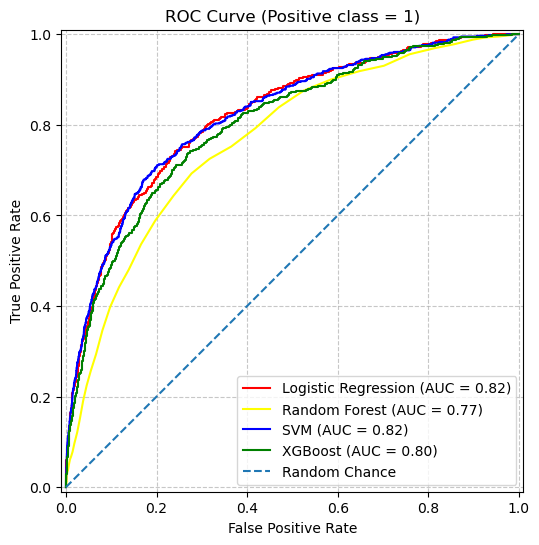

In [61]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 6))

RocCurveDisplay.from_predictions(y_test, LR_prob, name="Logistic Regression", ax=ax, color="red")
RocCurveDisplay.from_predictions(y_test, RF_prob, name="Random Forest", ax=ax, color="yellow")
RocCurveDisplay.from_predictions(y_test, SVM_prob, name="SVM", ax=ax, color="blue")
RocCurveDisplay.from_predictions(y_test, xgb_prob, name="XGBoost", ax=ax, color="green")

ax.plot([0, 1], [0, 1], "--", label="Random Chance")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve (Positive class = 1)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.7)

plt.show()

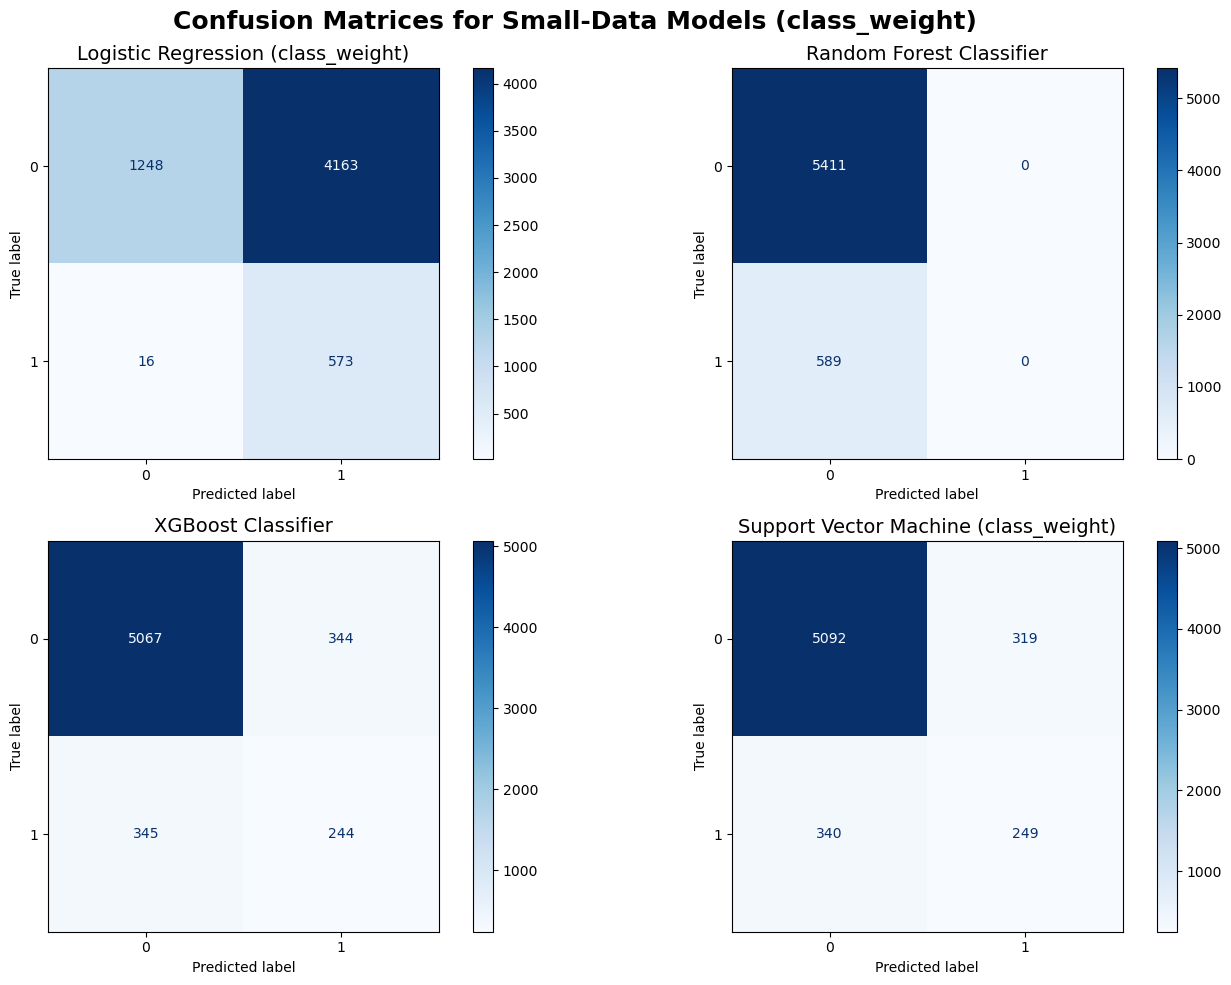

In [88]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Compute confusion matrices
cm_LR  = confusion_matrix(y_test, LogReg_final_pred)       # Logistic Regression
cm_RF  = confusion_matrix(y_test, RF_pred)       # Random Forest
cm_XGB = confusion_matrix(y_test, xgb_pred)      # XGBoost
cm_SVM = confusion_matrix(y_test, SVM_pred)      # SVM (class_weight)

# 2. Create display objects
disp_LR  = ConfusionMatrixDisplay(confusion_matrix=cm_LR,  display_labels=[0, 1])
disp_RF  = ConfusionMatrixDisplay(confusion_matrix=cm_RF,  display_labels=[0, 1])
disp_XGB = ConfusionMatrixDisplay(confusion_matrix=cm_XGB, display_labels=[0, 1])
disp_SVM = ConfusionMatrixDisplay(confusion_matrix=cm_SVM, display_labels=[0, 1])

# 3. Plot in a 2×2 grid
fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(14, 10))
fig.suptitle("Confusion Matrices for Small-Data Models (class_weight)", 
             fontsize=18, fontweight='bold')

disp_LR.plot(ax=axes[0,0], cmap='Blues')
axes[0,0].set_title("Logistic Regression (class_weight)", fontsize=14)

disp_RF.plot(ax=axes[0,1], cmap='Blues')
axes[0,1].set_title("Random Forest Classifier", fontsize=14)

disp_XGB.plot(ax=axes[1,0], cmap='Blues')
axes[1,0].set_title("XGBoost Classifier", fontsize=14)

disp_SVM.plot(ax=axes[1,1], cmap='Blues')
axes[1,1].set_title("Support Vector Machine (class_weight)", fontsize=14)

fig.tight_layout()
plt.show()


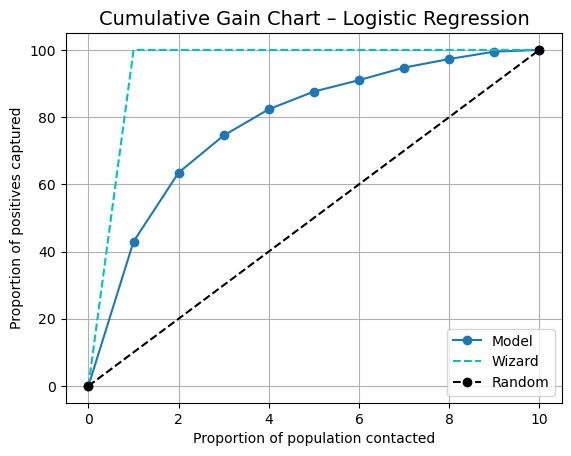

In [62]:
kds.metrics.plot_cumulative_gain(y_test, LR_prob)
plt.title("Cumulative Gain Chart – Logistic Regression", fontsize=14)
plt.xlabel("Proportion of population contacted")
plt.ylabel("Proportion of positives captured")
plt.show()


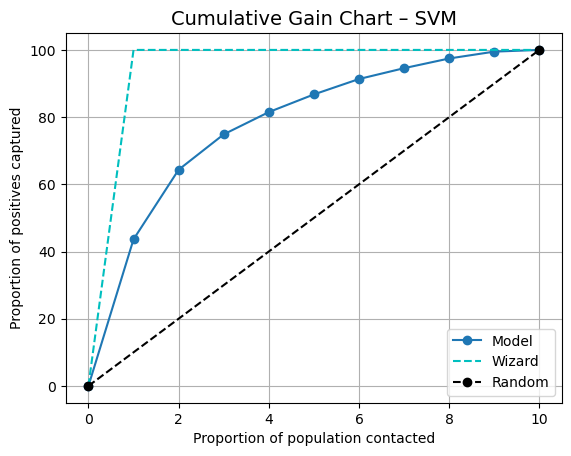

In [63]:
kds.metrics.plot_cumulative_gain(y_test, SVM_prob)
plt.title("Cumulative Gain Chart – SVM", fontsize=14)
plt.xlabel("Proportion of population contacted")
plt.ylabel("Proportion of positives captured")
plt.show()


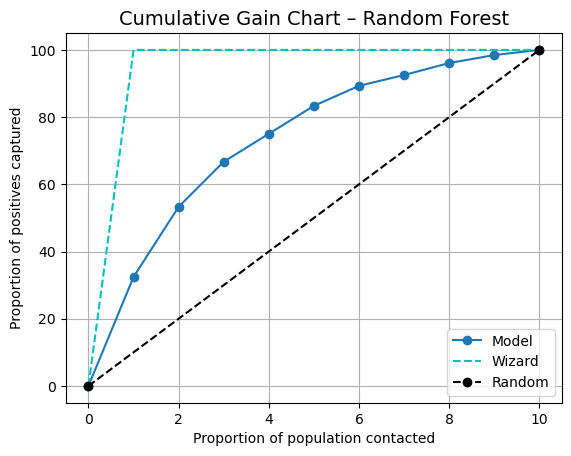

In [64]:
kds.metrics.plot_cumulative_gain(y_test, RF_prob)
plt.title("Cumulative Gain Chart – Random Forest", fontsize=14)
plt.xlabel("Proportion of population contacted")
plt.ylabel("Proportion of positives captured")
plt.show()


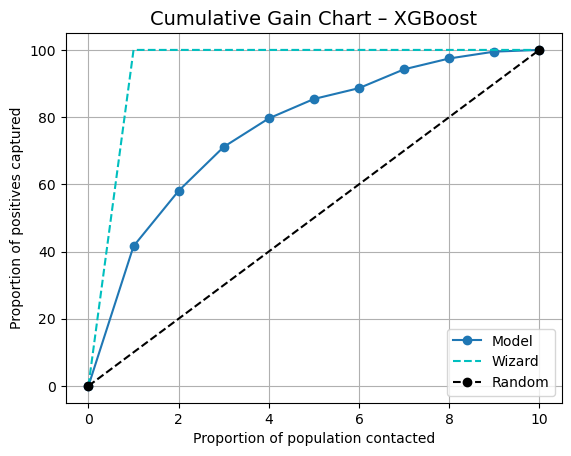

In [65]:
kds.metrics.plot_cumulative_gain(y_test, xgb_prob)
plt.title("Cumulative Gain Chart – XGBoost", fontsize=14)
plt.xlabel("Proportion of population contacted")
plt.ylabel("Proportion of positives captured")
plt.show()


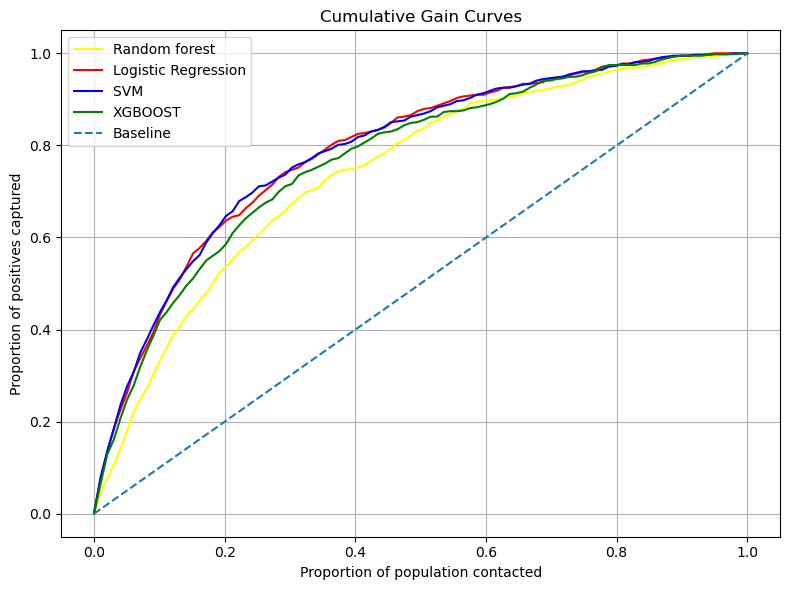

In [66]:
# Define a function to compute the cumulative gain curve
def cumulative_gains(y_true, y_prob, resolution=100):
    # Sort the prediction probs from highest to lowest and store the corresponding indices
    order = np.argsort(y_prob)[::-1]

    # Reorder the true labels (actual target values) so they match the sorted scores
    y_sorted = np.array(y_true)[order]

    # Compute how many positives have been captured
    cum_positives = np.cumsum(y_sorted)

    # Count the total number of positive examples in the dataset
    total_positives = y_sorted.sum()
    
    # Create evenly spaced points between 0 and 1 representing percentages of the population contacted
    perc_population = np.linspace(0, 1, resolution)

    # Convert each population percentage into the corresponding number of individuals
    cutoff = (perc_population * len(y_true)).astype(int)

    # For each cutoff, compute the fraction of all positives has been captured
    gains = cum_positives[np.clip(cutoff - 1, 0, None)] / total_positives
    return perc_population, gains

# curves
x_rf, g_rf  = cumulative_gains(y_test, RF_prob)
x_lr, g_lr  = cumulative_gains(y_test, LR_prob)
x_svm, g_svm = cumulative_gains(y_test, SVM_prob)
x_xgb, g_xgb = cumulative_gains(y_test, xgb_prob)

plt.figure(figsize=(8, 6))
plt.plot(x_rf,  g_rf,  label="Random forest", color="yellow")
plt.plot(x_lr,  g_lr,  label="Logistic Regression", color="red")
plt.plot(x_svm, g_svm, label="SVM ", color="blue")
plt.plot(x_xgb,  g_xgb,  label="XGBOOST", color="green")
plt.plot([0, 1], [0, 1], '--', label="Baseline")

plt.xlabel("Proportion of population contacted")
plt.ylabel("Proportion of positives captured")
plt.title("Cumulative Gain Curves")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

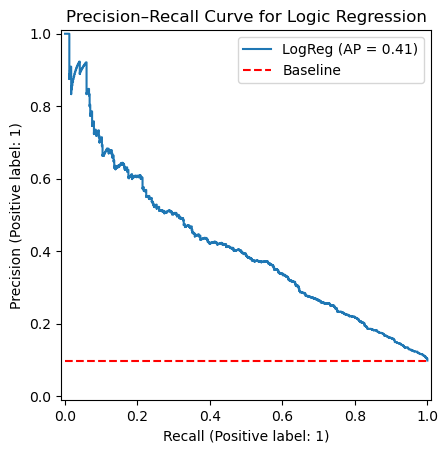

In [67]:
from sklearn.metrics import PrecisionRecallDisplay
#precision–recall curve of Logic regression modeling
fig, ax = plt.subplots()

# create the curve on your own axes
disp = PrecisionRecallDisplay.from_predictions(y_test, LR_prob, name="LogReg", ax=ax)

baseline = y_test.mean()
ax.hlines(baseline, xmin=0, xmax=1, colors='red', linestyles='--', label='Baseline')

ax.set_title("Precision–Recall Curve for Logic Regression")
ax.legend()

plt.show()

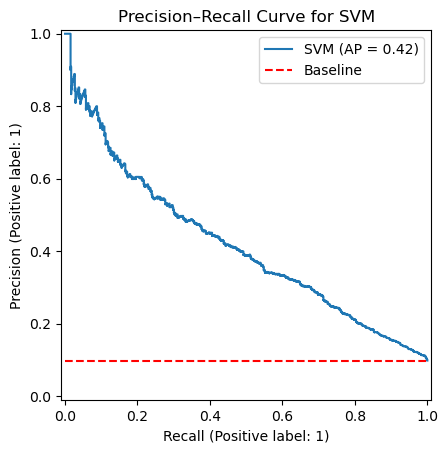

In [68]:
from sklearn.metrics import PrecisionRecallDisplay
#precision–recall curve of SVM modeling
fig, ax = plt.subplots()

# create the curve on your own axes
disp = PrecisionRecallDisplay.from_predictions(y_test, SVM_prob, name="SVM", ax=ax)

baseline = y_test.mean()
ax.hlines(baseline, xmin=0, xmax=1, colors='red', linestyles='--', label='Baseline')

ax.set_title("Precision–Recall Curve for SVM")
ax.legend()

plt.show()

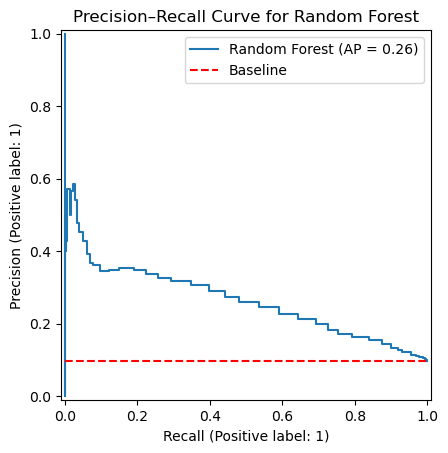

In [69]:
from sklearn.metrics import PrecisionRecallDisplay
#precision–recall curve of Random Forest modeling
fig, ax = plt.subplots()

# create the curve on your own axes
disp = PrecisionRecallDisplay.from_predictions(y_test, RF_prob, name="Random Forest", ax=ax)

baseline = y_test.mean()
ax.hlines(baseline, xmin=0, xmax=1, colors='red', linestyles='--', label='Baseline')

ax.set_title("Precision–Recall Curve for Random Forest")
ax.legend()

plt.show()

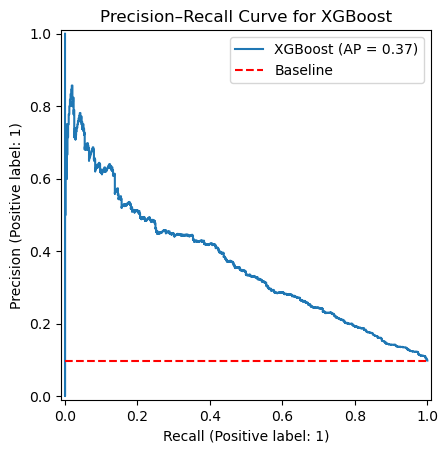

In [70]:
from sklearn.metrics import PrecisionRecallDisplay
#precision–recall curve of XGBoost modeling
fig, ax = plt.subplots()

# create the curve on your own axes
disp = PrecisionRecallDisplay.from_predictions(y_test, xgb_prob, name="XGBoost", ax=ax)

baseline = y_test.mean()
ax.hlines(baseline, xmin=0, xmax=1, colors='red', linestyles='--', label='Baseline')

ax.set_title("Precision–Recall Curve for XGBoost")
ax.legend()

plt.show()

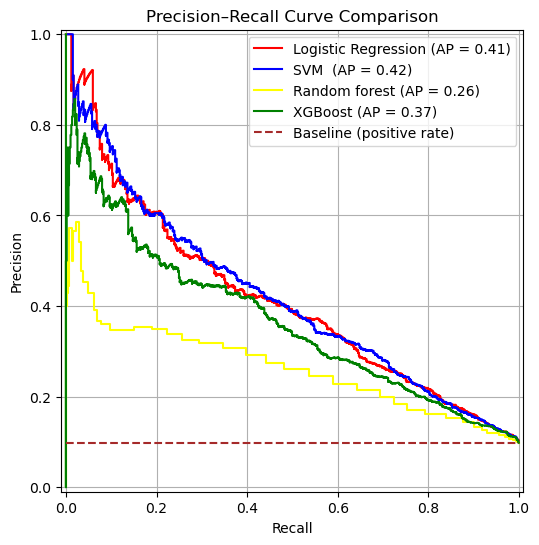

In [71]:
# Precision-Recall
fig, ax = plt.subplots(figsize=(7, 6))
#precision–recall curve of all modeling
PrecisionRecallDisplay.from_predictions(y_test, LR_prob, ax=ax, name="Logistic Regression", color="red")
PrecisionRecallDisplay.from_predictions(y_test, SVM_prob, ax=ax, name="SVM ", color="blue")
PrecisionRecallDisplay.from_predictions(y_test, RF_prob, ax=ax, name="Random forest", color="yellow")
PrecisionRecallDisplay.from_predictions(y_test, xgb_prob, ax=ax, name="XGBoost", color="green")

baseline = y_test.mean()
ax.hlines(baseline, xmin=0, xmax=1,colors="brown", linestyles="--", label="Baseline (positive rate)")

ax.set_title("Precision–Recall Curve Comparison")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
ax.grid(True)
plt.show()

In [79]:
# Create a comprehensive comparison table
comparison_df = pd.DataFrame({
   'Model': ['Logistic Regression', 'SVM', 'Random Forest', 'XGBoost'],
    'Threshold': [0.1, 0.1, 0.1, 0.1],
    'Accuracy':  [accuracy_logreg, accuracy_svm, accuracy_rf, accuracy_xgb],
    'Precision': [precision_logreg, precision_svm, precision_rf, precision_xgb],
    'Recall':    [recall_logreg, recall_svm, recall_rf, recall_xgb],
    'F1-Score':  [f1_logreg, f1_svm, f1_rf, f1_xgb],
    'AUC':       [auc_LogReg, auc_SVM, auc_RF, auc_xgb]
})

print("="*80)
print("CLASS WEIGHT MODEL PERFORMANCE COMPARISON")
print("="*80)
print(comparison_df.to_string(index=False))
print("="*80)

# Identify the best model for each metric
print("\nBest Models by Metric:")
print(f"Highest Accuracy:  {comparison_df.loc[comparison_df['Accuracy'].idxmax(), 'Model']} ({comparison_df['Accuracy'].max():.4f})")
print(f"Highest Precision: {comparison_df.loc[comparison_df['Precision'].idxmax(), 'Model']} ({comparison_df['Precision'].max():.4f})")
print(f"Highest Recall:    {comparison_df.loc[comparison_df['Recall'].idxmax(), 'Model']} ({comparison_df['Recall'].max():.4f})")
print(f"Highest F1-Score:  {comparison_df.loc[comparison_df['F1-Score'].idxmax(), 'Model']} ({comparison_df['F1-Score'].max():.4f})")
print(f"Highest AUC:       {comparison_df.loc[comparison_df['AUC'].idxmax(), 'Model']} ({comparison_df['AUC'].max():.4f})")
print("="*80)

CLASS WEIGHT MODEL PERFORMANCE COMPARISON
              Model  Threshold  Accuracy  Precision   Recall  F1-Score      AUC
Logistic Regression        0.1  0.761333   0.252786 0.731749  0.375763 0.820486
                SVM        0.1  0.755000   0.247853 0.735144  0.370719 0.820991
      Random Forest        0.1  0.646500   0.183209 0.752122  0.294646 0.767486
            XGBoost        0.1  0.478000   0.145526 0.886248  0.250000 0.800805

Best Models by Metric:
Highest Accuracy:  Logistic Regression (0.7613)
Highest Precision: Logistic Regression (0.2528)
Highest Recall:    XGBoost (0.8862)
Highest F1-Score:  Logistic Regression (0.3758)
Highest AUC:       SVM (0.8210)
